<a href="https://colab.research.google.com/github/kalxdoc/Research_pac1/blob/main/lab_report_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mental Health Analysis: Comparing Encoding Techniques across ML Models

This notebook follows the structure of the **Lab 3 EDA** notebook and applies the encoding techniques from **Lab 2** to the *Mental Stress* survey dataset.

### Objectives
- Understand and clean the dataset (EDA)
- Encode the categorical survey answers four different ways: **Label, One-Hot, Hybrid, Ordinal**
- Print the raw cleaned data, then the encoded data after every encoder, so the difference is visible
- Train **Decision Tree, KNN and MLP (neural network)** on every encoding, one by one
- Compare results with a **4 encoder × 3 model correlation / result table**

**Target variable:** `Mental_Health_Rating` (Poor < Fair < Good < Excellent), a 4-class problem.

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 1: Import Required Libraries

In [8]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 40)

## Mount the drive
Only needed in Google Colab. Outside Colab this cell is skipped automatically.

In [9]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ModuleNotFoundError:
    print('Not running in Colab, skipping drive mount.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Step 2: Load the Dataset
The cell looks for the CSV in your Drive folder first, then in the current folder.

In [10]:
import os
CANDIDATES = [
"/content/drive/MyDrive/lab FA/Copy of DS422_Dataset_Mental Stress.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
print('Loading:', DATA_PATH)
df = pd.read_csv(DATA_PATH)

Loading: /content/drive/MyDrive/lab FA/Copy of DS422_Dataset_Mental Stress.csv


## Step 3: Explore the Dataset

In [11]:
df.head()

,Timestamp,1. How often do you feel overwhelmed by academic pressure?\nআপনি কত ঘন ঘন একাডেমিক চাপে ভুগছেন বলে মনে করেন?,2. How would you rate your overall mental health in the past month?\nগত এক মাসে আপনার সামগ্রিক মানসিক স্বাস্থ্য কেমন ছিল বলে মনে করেন?,3. How frequently do you experience stress related to studies?\nআপনি কত ঘন ঘন পড়াশোনা নিয়ে মানসিক চাপ অনুভব করেন?,4. How comfortable do you feel discussing your mental health concerns with friends or family?\nবন্ধু বা পরিবারের সঙ্গে আপনার মানসিক স্বাস্থ্যের বিষয় আলোচনা করতে কতটা স্বাচ্ছন্দ্যবোধ করেন?,"5. Do you have access to professional mental health support (e.g., counseling services, therapy)?\nআপনার কি পেশাদার মানসিক স্বাস্থ্য সহায়তার (যেমন কাউন্সেলিং বা থেরাপি) সুযোগ আছে?",6. How often do you feel socially isolated or lonely?\nআপনি কত ঘন ঘন একাকিত্ব বা সামাজিক বিচ্ছিন্নতা অনুভব করেন?,7. Do you engage in physical activities or exercises to relieve stress?\nআপনি কি স্ট্রেস কমাতে শরীরচর্চা বা শারীরিক কার্যক্রমে অংশ নেন?,8. How many hours of sleep do you usually get on school days?\nস্কুল চলাকালীন দিনে আপনি সাধারণত কত ঘণ্টা ঘুমান?,"9. Have you experienced symptoms of depression (e.g., persistent sadness, loss of interest, fatigue) in the past few months?\nগত কয়েক মাসে কি আপনি বিষণ্ণতার লক্ষণ (যেমন দীর্ঘস্থায়ী দুঃখ, আগ্রহ হারানো, ক্লান্তি) অনুভব করেছেন?","10. Do you use social media, and do you feel it impacts your mental health?\nআপনি কি সোশ্যাল মিডিয়া ব্যবহার করেন এবং এটি আপনার মানসিক স্বাস্থ্যে প্রভাব ফেলে বলে মনে করেন?",11. How well do you manage time between studies and personal life?\nপড়াশোনা ও ব্যক্তিগত জীবনের মধ্যে সময় কতটা ভালোভাবে ম্যানেজ করেন?,12. Have you ever sought professional help for mental health concerns?\nআপনি কি কখনও মানসিক স্বাস্থ্য সমস্যা নিয়ে পেশাদার সাহায্য চেয়েছেন?,13. Do you participate in extracurricular activities that help reduce stress?\nআপনি কি স্ট্রেস কমাতে সহায়ক অতিরিক্ত কার্যকলাপে অংশগ্রহণ করেন?,14. Do financial concerns impact your mental health?\nআর্থিক চিন্তাভাবনা কি আপনার মানসিক স্বাস্থ্যে প্রভাব ফেলে?,15. Have you ever experienced bullying or discrimination that affected your mental health?\nআপনি কি কখনও এমন হয়রানি বা বৈষম্যের শিকার হয়েছেন যা আপনার মানসিক স্বাস্থ্যে প্রভাব ফেলেছে?,"16. Do you have a strong support system (friends, family, mentors) for mental health challenges?\nআপনার কি মানসিক স্বাস্থ্য চ্যালেঞ্জ মোকাবিলার জন্য একটি শক্তিশালী সহায়ক ব্যবস্থা রয়েছে (বন্ধু, পরিবার, মেন্টর)?",17. Have you noticed a change in your eating habits due to stress or mental health concerns?\nস্ট্রেস বা মানসিক স্বাস্থ্য সমস্যার কারণে কি আপনি খাদ্যাভ্যাসে পরিবর্তন লক্ষ্য করেছেন?,18. What coping mechanisms do you use for mental health challenges? (Select the most common one)\nআপনি মানসিক স্বাস্থ্য সমস্যার জন্য কোন কৌশল ব্যবহার করেন? (সাধারণত ব্যবহৃত একটি নির্বাচন করুন),19. How confident are you in managing your mental health challenges independently?\nআপনি স্বতন্ত্রভাবে মানসিক স্বাস্থ্য সমস্যাগুলি কতটা আত্মবিশ্বাসের সাথে পরিচালনা করতে পারেন বলে মনে করেন?,20. What additional support would you like to see for student mental health?\nশিক্ষার্থীদের মানসিক স্বাস্থ্য সহায়তার জন্য আপনি আর কী দেখতে চান?
0,5/18/2025 22:11,Often / প্রায়ই,Fair / মোটামুটি,Occasionally / মাঝে মাঝে,Neutral / নিরপেক্ষ,"No, and I don’t need it | না, এবং আ...",Sometimes / কখনো কখনো,Occasionally / মাঝে মাঝে,6-8 hours / ৬-৮ ঘণ্টা,Moderate symptoms / মাঝারি লক্ষণ,"Yes, negatively / হ্যাঁ, নেতিবাচকভাবে",Poorly / খারাপভাবে,"No, and I do not plan to | না, এবং আ...",Rarely | খুব কম,A lot | অনেকটা,Prefer not to say | বলতে অনিচ্ছুক,Sometimes | মাঝে মাঝে,Slight changes | সামান্য পরিবর্তন,No specific coping mechanism | নির্দ...,Somewhat confident | কিছুটা আত্মবিশ্...,Stress management workshops | স্ট্রে...
1,8/2/2025 22:28,Sometimes / কখনো কখনো,Poor / খারাপ,Occasionally / মাঝে মাঝে,Somewhat comfortable / কিছুটা স্বাচ্...,"No, and I don’t need it | না, এবং আম...",Never / কখনো না,Never / কখনো না,6-8 hours / ৬-৮ ঘণ্টা,Moderate symptoms / মাঝারি লক্ষণ,"Yes, negatively / হ্যাঁ, নেতি

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1950 entries, 0 to 1949
Data columns (total 21 columns):
 #   Column                                                                                                                                                                                                                             Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                                             --------------  ----- 
 0   Timestamp                                                                                                                                                                                                                          1950 non-null   object
 1   1. How often do you feel overwhelmed by academic pressure?
আপনি কত ঘন ঘন একাডেমিক চাপে ভুগছেন বলে মনে করেন?                

## Step 4: Understanding Data Structure
We check the shape, drop the `Timestamp`, give the 20 long bilingual questions short names, and look at missing values.

In [13]:
print('Shape (rows, columns):', df.shape)

Shape (rows, columns): (1950, 21)


In [14]:
df = df.drop('Timestamp', axis=1)
print('Total missing cells:', int(df.isnull().sum().sum()), '| rows with at least one missing value:', int(df.isnull().any(axis=1).sum()))

Total missing cells: 68 | rows with at least one missing value: 57


**Renaming.** The 20 questions are renamed *by position* (Q1 to Q20). Note: the EDA notebook's rename dictionary gave Q12 to Q16 names that do not match their question text (for example Q13 is about extracurricular activities but was named `MH_Affects_Performance`). Here every name matches its question. The mapping is printed so you can verify it.

In [15]:
names = ['Academic_Pressure_Freq', 'Mental_Health_Rating', 'Study_Stress_Freq', 'Comfort_Discussing_MH',
         'Access_Support', 'Social_Isolation_Freq', 'Physical_Activity', 'Sleep_Hours',
         'Depression_Symptoms', 'Social_Media_Impact_Perception', 'Time_Management_Ability',
         'Sought_Professional_Help', 'Extracurricular_Activities', 'Financial_Stress_Impact',
         'Bullying_Discrimination', 'Support_System', 'Appetite_Change_Stress',
         'Primary_Coping_Mechanism', 'Coping_Confidence', 'Needed_Additional_Support']
assert len(names) == df.shape[1]

questions = [c.split('\n')[0].strip() for c in df.columns]      # English part of each question
mapping = pd.DataFrame({'new_name': names, 'question': questions})
mapping.index = [f'Q{i+1}' for i in range(len(names))]
pd.set_option('display.max_colwidth', 110)
print(mapping.to_string())
pd.set_option('display.max_colwidth', 40)

df.columns = names
TARGET = 'Mental_Health_Rating'

                           new_name                                                                                                                      question
Q1           Academic_Pressure_Freq                                                                    1. How often do you feel overwhelmed by academic pressure?
Q2             Mental_Health_Rating                                                           2. How would you rate your overall mental health in the past month?
Q3                Study_Stress_Freq                                                                3. How frequently do you experience stress related to studies?
Q4            Comfort_Discussing_MH                                 4. How comfortable do you feel discussing your mental health concerns with friends or family?
Q5                   Access_Support                             5. Do you have access to professional mental health support (e.g., counseling services, therapy)?
Q6            Social_Isolati

In [16]:
df.isnull().sum()

,0
Academic_Pressure_Freq,0
Mental_Health_Rating,0
Study_Stress_Freq,0
Comfort_Discussing_MH,0
Access_Support,0
Social_Isolation_Freq,0
Physical_Activity,7
Sleep_Hours,3
Depression_Symptoms,3
Social_Media_Impact_Perception,0


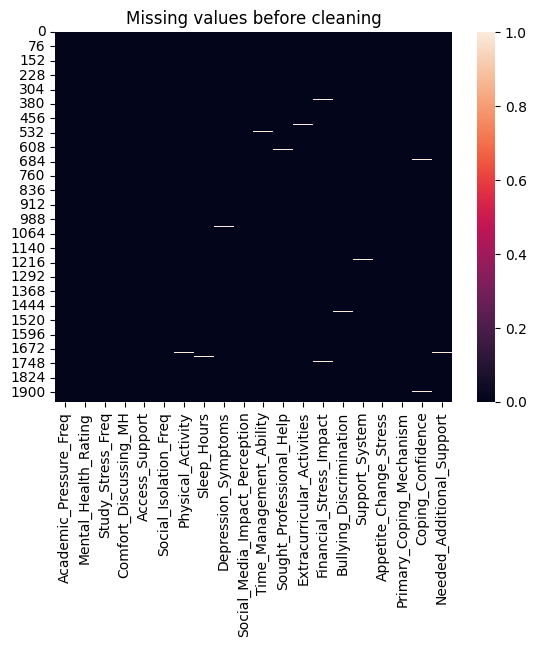

In [17]:
sns.heatmap(df.isnull())
plt.title('Missing values before cleaning')
plt.show()

## Step 5: Data Cleaning
Real-world data contains missing values, mixed languages, typos and junk answers. We handle each one explicitly.

### 5.1 Missing values

In [18]:
n_before = len(df)
df.dropna(inplace=True)
print(f'Rows before: {n_before} | after dropna: {len(df)} | removed: {n_before - len(df)}')
df.isnull().sum().sum()

Rows before: 1950 | after dropna: 1893 | removed: 57


np.int64(0)

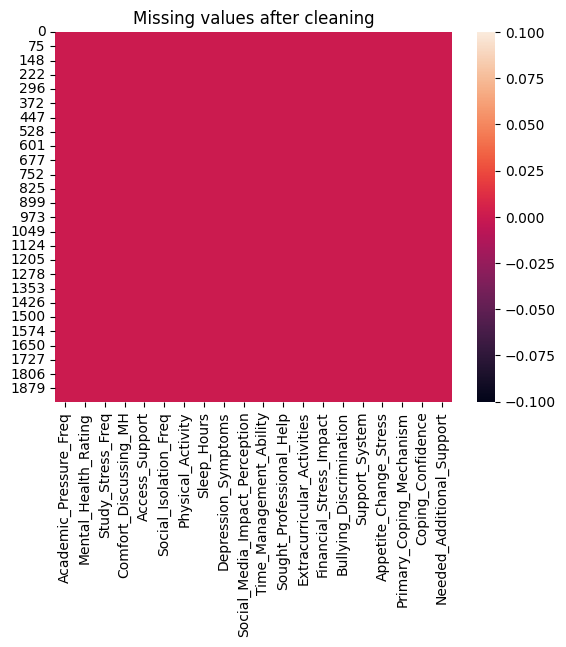

In [19]:
sns.heatmap(df.isnull())
plt.title('Missing values after cleaning')
plt.show()

### 5.2 Text cleaning: removing Bangla text and special symbols
Answers look like `Often / প্রায়ই` or `Rarely | খুব কম`. A regular expression keeps only the English part before the `/` or `|` symbol. Three extra fixes are applied:
- the typographic apostrophe `’` is replaced by `'` so `don’t` and `don't` are the same category
- stray option letters such as `B) Mild symptoms` are reduced to `Mild symptoms`
- leading/trailing spaces are stripped (`' Neutral'` and `'Neutral'` were counted as different values)

In [20]:
def clean_text(text):
    s = str(text).replace('\u2019', "'")
    s = re.split(r'\s*[/|]\s*(?=[^\x00-\x7F])', s)[0]   # drop the Bangla translation
    s = re.sub(r'^[A-Za-z]\)\s*', '', s)                  # 'B) Mild symptoms' -> 'Mild symptoms'
    return s.strip()

before = df[['Sleep_Hours', 'Depression_Symptoms', 'Comfort_Discussing_MH']].head(4)
for col in df.columns:                     # every column holds text answers
    df[col] = df[col].apply(clean_text)
after = df[['Sleep_Hours', 'Depression_Symptoms', 'Comfort_Discussing_MH']].head(4)
print('BEFORE cleaning'); print(before); print('\nAFTER cleaning'); print(after)

BEFORE cleaning
             Sleep_Hours               Depression_Symptoms                    Comfort_Discussing_MH
0  6-8 hours / ৬-৮ ঘণ্টা  Moderate symptoms / মাঝারি লক্ষণ                       Neutral / নিরপেক্ষ
1  6-8 hours / ৬-৮ ঘণ্টা  Moderate symptoms / মাঝারি লক্ষণ  Somewhat comfortable / কিছুটা স্বাচ্...
2  6-8 hours / ৬-৮ ঘণ্টা     Mild symptoms / সামান্য লক্ষণ  Somewhat comfortable / কিছুটা স্বাচ্...
3  6-8 hours / ৬-৮ ঘণ্টা     Mild symptoms / সামান্য লক্ষণ                       Neutral / নিরপেক্ষ

AFTER cleaning
  Sleep_Hours Depression_Symptoms Comfort_Discussing_MH
0   6-8 hours   Moderate symptoms               Neutral
1   6-8 hours   Moderate symptoms  Somewhat comfortable
2   6-8 hours       Mild symptoms  Somewhat comfortable
3   6-8 hours       Mild symptoms               Neutral


### 5.3 Invalid answers
`Option 8` is not a real answer to Q11 (time management); it is a leftover placeholder. Those rows are removed.

In [21]:
print(df['Time_Management_Ability'].value_counts())
n = (df['Time_Management_Ability'] == 'Option 8').sum()
df = df[df['Time_Management_Ability'] != 'Option 8'].reset_index(drop=True)
print(f'\nRemoved {n} rows with the invalid answer "Option 8". Rows left: {len(df)}')

Time_Management_Ability
Somewhat well    698
Poorly           437
Very well        331
Very poorly      233
Option 8         194
Name: count, dtype: int64

Removed 194 rows with the invalid answer "Option 8". Rows left: 1699


### 5.4 Duplicate rows (important)
Before modelling we check for duplicated survey responses. If identical rows land in both the training and test set, a model can simply *memorise* them and the test score becomes meaningless.

In [22]:
n_dup = df.duplicated().sum()
print(f'Rows after cleaning       : {len(df)}')
print(f'Exact duplicate rows      : {n_dup}  ({n_dup/len(df):.1%})')
print(f'Unique survey responses   : {len(df) - n_dup}')

Rows after cleaning       : 1699
Exact duplicate rows      : 1105  (65.0%)
Unique survey responses   : 594


Most rows are duplicates. We therefore keep **two versions** of the cleaned data and evaluate the models on both:

| Name | Content | Purpose |
|---|---|---|
| `df_dup` | cleaned data, duplicates kept | what the EDA-style workflow gives; test scores will be **inflated** by memorisation |
| `df_uni` | cleaned data, duplicates removed | **honest** evaluation, no row can appear in both train and test |

Visualisations in Step 6 use `df_dup` (as in the EDA notebook). The honest results are the ones from `df_uni`.

In [23]:
df_dup = df.copy()
df_uni = df.drop_duplicates().reset_index(drop=True)
print('df_dup:', df_dup.shape, '| df_uni:', df_uni.shape)

df_dup: (1699, 20) | df_uni: (594, 20)


In [24]:
# Cleaned categorical data used from here on (this is the "original raw data after cleaning")
df = df_dup.copy()
df

,Academic_Pressure_Freq,Mental_Health_Rating,Study_Stress_Freq,Comfort_Discussing_MH,Access_Support,Social_Isolation_Freq,Physical_Activity,Sleep_Hours,Depression_Symptoms,Social_Media_Impact_Perception,Time_Management_Ability,Sought_Professional_Help,Extracurricular_Activities,Financial_Stress_Impact,Bullying_Discrimination,Support_System,Appetite_Change_Stress,Primary_Coping_Mechanism,Coping_Confidence,Needed_Additional_Support
0,Often,Fair,Occasionally,Neutral,"No, and I don't need it",Sometimes,Occasionally,6-8 hours,Moderate symptoms,"Yes, negatively",Poorly,"No, and I do not plan to",Rarely,A lot,Prefer not to say,Sometimes,Slight changes,No specific coping mechanism,Somewhat confident,Stress management workshops
1,Sometimes,Poor,Occasionally,Somewhat comfortable,"No, and I don't need it",Never,Never,6-8 hours,Moderate symptoms,"Yes, negatively",Poorly,"No, but I am considering it",Never,A lot,"Yes, and it has affected me signific...",Rarely,Slight changes,Talking to someone,Somewhat confident,Awareness programs
2,Sometimes,Good,Occasionally,Somewhat comfortable,"Yes, and I use it",Never,Rarely,6-8 hours,Mild symptoms,"Yes, negatively",Poorly,"Yes, and it helped","Yes, occasionally",Somewhat,"Yes, but I have coped well",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Peer support groups
3,Sometimes,Fair,Occasionally,Neutral,"No, but I would like access",Sometimes,Occasionally,6-8 hours,Mild symptoms,"Yes, negatively",Poorly,"Yes, but it did not help","Yes, frequently",Somewhat,"Yes, but I have coped well",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Awareness programs
4,Always,Fair,Almost all the time,Somewhat comfortable,"No, and I don't need it",Always,Never,4-6 hours,Severe symptoms,"Yes, negatively",Poorly,"No, but I am considering it",Rarely,Extremely,"Yes, and it has affected me signific...",No,Extreme changes,No specific coping mechanism,Not confident at all,More counseling services
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1694,Sometimes,Fair,Occasionally,Neutral,"No, but I would like access",Sometimes,Occasionally,6-8 hours,Mild symptoms,"Yes, negatively",Poorly,"Yes, but it did not help","Yes, frequently",Somewhat,"Yes, but I have coped well",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Awareness programs
1695,Always,Fair,Almost all the time,Somewhat comfortable,"No, and I don't need it",Always,Never,4-6 hours,Severe symptoms,"Yes, negatively",Poorly,"No, but I am considering it",Rarely,Extremely,"Yes, and it has affected me signific...",No,Extreme changes,No specific coping mechanism,Not confident at all,More counseling services
1696,Often,Good,Never,Very comfortable,"Yes, and I use it",Always,Regularly,More than 8 hours,No,"Yes, positively",Very well,"Yes, and it helped","Yes, frequently",Extremely,"Yes, but I have coped well","Yes, always",Significant changes,Physical activities,Somewhat confident,More counseling services
1697,Sometimes,Good,Occasionally,Neutral,"No, but I would like access",Sometimes,Occasionally,6-8 hours,Mild symptoms,"Yes, positively",Somewhat well,"No, but I am considering it","Yes, occasionally",Somewhat,"Yes, and it has affected me signific...",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Awareness programs


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1699 entries, 0 to 1698
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype 
---  ------                          --------------  ----- 
 0   Academic_Pressure_Freq          1699 non-null   object
 1   Mental_Health_Rating            1699 non-null   object
 2   Study_Stress_Freq               1699 non-null   object
 3   Comfort_Discussing_MH           1699 non-null   object
 4   Access_Support                  1699 non-null   object
 5   Social_Isolation_Freq           1699 non-null   object
 6   Physical_Activity               1699 non-null   object
 7   Sleep_Hours                     1699 non-null   object
 8   Depression_Symptoms             1699 non-null   object
 9   Social_Media_Impact_Perception  1699 non-null   object
 10  Time_Management_Ability         1699 non-null   object
 11  Sought_Professional_Help        1699 non-null   object
 12  Extracurricular_Activities      1699 non-null   

## Step 6: Data Visualization
Graphs help us find trends, class imbalance and relationships between variables.

The order of the answer categories (low to high) is defined once here. It is reused for plotting and, later, for ordinal encoding.

In [26]:
TARGET_ORDER = ['Poor', 'Fair', 'Good', 'Excellent']

ORDER = {
    'Academic_Pressure_Freq'        : ['Rarely', 'Sometimes', 'Often', 'Always'],
    'Study_Stress_Freq'             : ['Never', 'Occasionally', 'Frequently', 'Almost all the time'],
    'Comfort_Discussing_MH'         : ['Uncomfortable', 'Neutral', 'Somewhat comfortable', 'Very comfortable'],
    'Access_Support'                : ["No, and I don't need it", 'No, but I would like access', "Yes, but I don't use it", 'Yes, and I use it'],
    'Social_Isolation_Freq'         : ['Never', 'Sometimes', 'Often', 'Always'],
    'Physical_Activity'             : ['Never', 'Rarely', 'Occasionally', 'Regularly'],
    'Sleep_Hours'                   : ['Less than 4 hours', '4-6 hours', '6-8 hours', 'More than 8 hours'],
    'Depression_Symptoms'           : ['No', 'Mild symptoms', 'Moderate symptoms', 'Severe symptoms'],
    'Social_Media_Impact_Perception': ['Yes, positively', 'I do not use social media', 'No impact', 'Yes, negatively'],
    'Time_Management_Ability'       : ['Very poorly', 'Poorly', 'Somewhat well', 'Very well'],
    'Sought_Professional_Help'      : ['No, and I do not plan to', 'No, but I am considering it', 'Yes, but it did not help', 'Yes, and it helped'],
    'Extracurricular_Activities'    : ['Never', 'Rarely', 'Yes, occasionally', 'Yes, frequently'],
    'Financial_Stress_Impact'       : ['No impact', 'Somewhat', 'A lot', 'Extremely'],
    'Bullying_Discrimination'       : ['No', 'Prefer not to say', 'Yes, but I have coped well', 'Yes, and it has affected me significantly'],
    'Support_System'                : ['No', 'Rarely', 'Sometimes', 'Yes, always'],
    'Appetite_Change_Stress'        : ['No change', 'Slight changes', 'Significant changes', 'Extreme changes'],
    'Primary_Coping_Mechanism'      : ['No specific coping mechanism', 'Talking to someone', 'Engaging in hobbies', 'Physical activities'],
    'Coping_Confidence'             : ['Not confident at all', 'Not very confident', 'Somewhat confident', 'Very confident'],
    'Needed_Additional_Support'     : ['Awareness programs', 'Peer support groups', 'Stress management workshops', 'More counseling services'],
}

# sanity check: every cleaned answer must be a known category
for col, cats in ORDER.items():
    unknown = set(df[col].unique()) - set(cats)
    assert not unknown, (col, unknown)
assert set(df[TARGET].unique()) == set(TARGET_ORDER)
print('All answers match the expected categories.')
print(df[TARGET].value_counts()[TARGET_ORDER])

All answers match the expected categories.
Mental_Health_Rating
Poor         298
Fair         568
Good         493
Excellent    340
Name: count, dtype: int64


### Relationship between features
Grouping two features and counting their combinations shows how one variable relates to the rating.

Mental_Health_Rating  Poor  Fair  Good  Excellent
Study_Stress_Freq                                
Never                   33    45    82        146
Occasionally            73   217   258         91
Frequently              61   196    94         38
Almost all the time    131   110    59         65


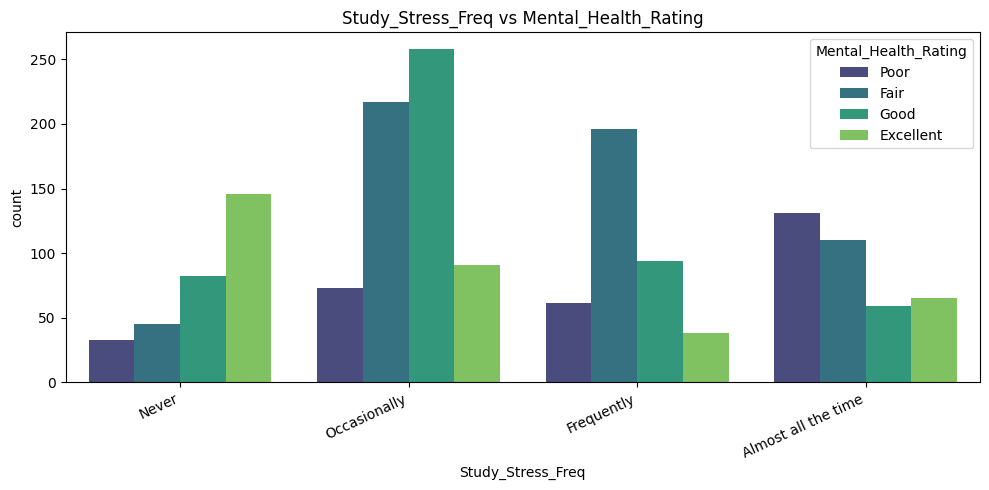

In [27]:
def compare_plot(feature):
    counts = df.groupby([feature, TARGET])[feature].count().reset_index(name='counts')
    print(counts.pivot(index=feature, columns=TARGET, values='counts')[TARGET_ORDER].loc[ORDER[feature]])
    plt.figure(figsize=(10, 5))
    sns.countplot(x=feature, hue=TARGET, data=df, order=ORDER[feature], hue_order=TARGET_ORDER, palette='viridis')
    plt.title(f'{feature} vs {TARGET}')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.show()

compare_plot('Study_Stress_Freq')

Mental_Health_Rating  Poor  Fair  Good  Excellent
Sleep_Hours                                      
Less than 4 hours       72    81    78         73
4-6 hours               84   202   115         76
6-8 hours               82   219   216         71
More than 8 hours       60    66    84        120


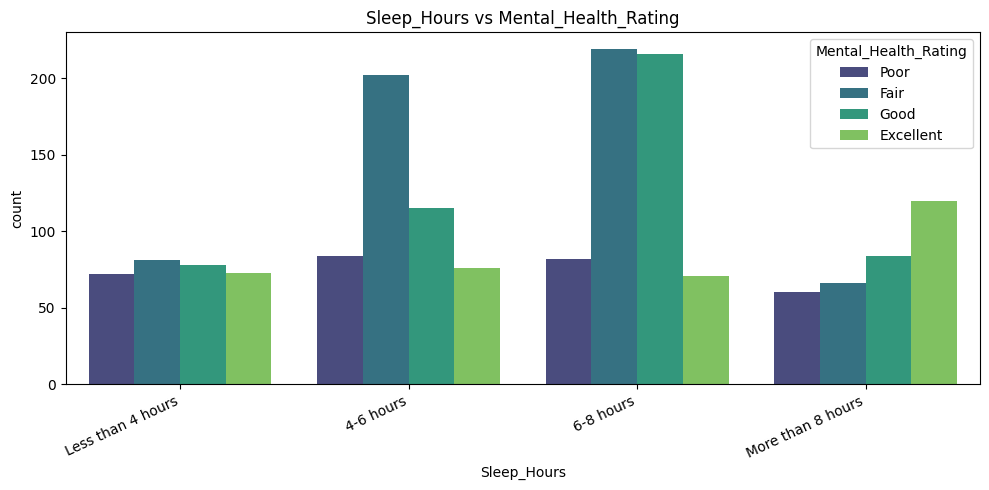

In [28]:
compare_plot('Sleep_Hours')

Mental_Health_Rating     Poor  Fair  Good  Excellent
Financial_Stress_Impact                             
No impact                  44    56   138        121
Somewhat                   56   187   201         62
A lot                      98   174    83         93
Extremely                 100   151    71         64


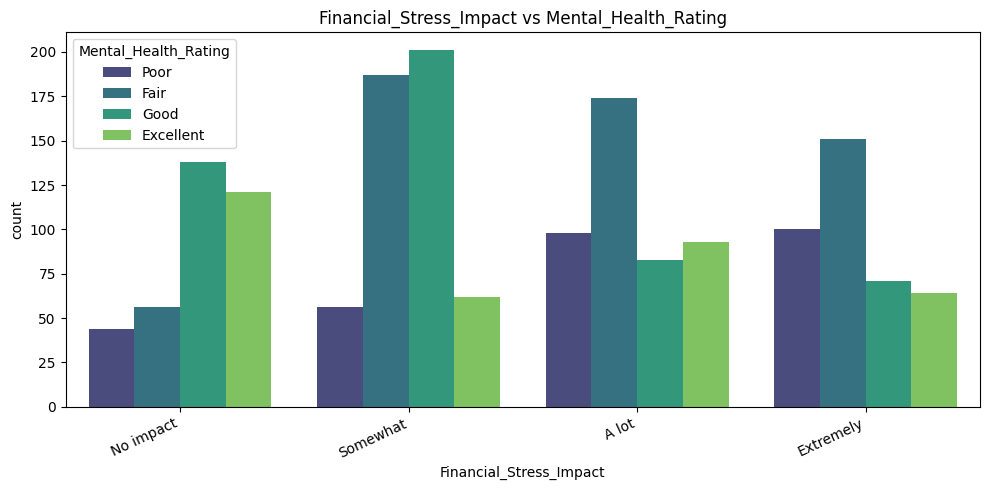

In [29]:
compare_plot('Financial_Stress_Impact')

Mental_Health_Rating            Poor  Fair  Good  Excellent
Social_Media_Impact_Perception                             
Yes, positively                   90   167   167        142
I do not use social media         38    41    45         66
No impact                         63   127   136         63
Yes, negatively                  107   233   145         69


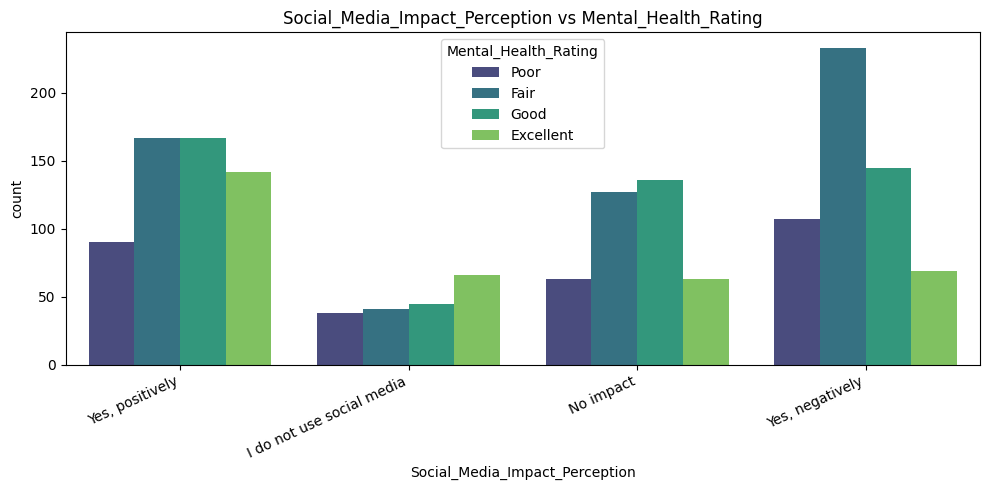

In [30]:
compare_plot('Social_Media_Impact_Perception')

### Distribution of feature values

Appetite_Change_Stress
Slight changes         584
No change              489
Significant changes    401
Extreme changes        225
Name: count, dtype: int64


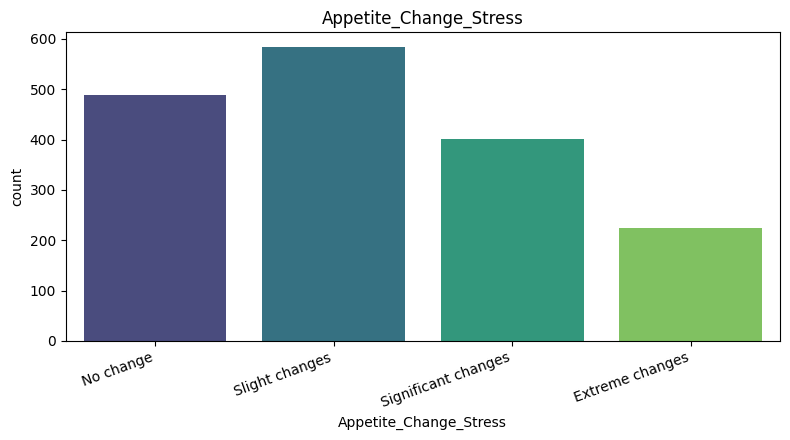

In [31]:
print(df['Appetite_Change_Stress'].value_counts())
plt.figure(figsize=(8, 4.5))
sns.countplot(x='Appetite_Change_Stress', data=df, order=ORDER['Appetite_Change_Stress'], palette='viridis')
plt.title('Appetite_Change_Stress')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

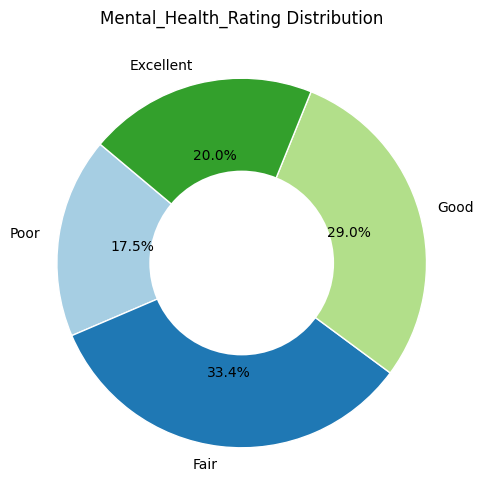

In [32]:
pct = df[TARGET].value_counts()[TARGET_ORDER]
pct = pct / pct.sum() * 100
plt.figure(figsize=(6, 6))
plt.pie(pct, labels=pct.index, autopct='%1.1f%%', colors=plt.cm.Paired.colors, startangle=140,
        wedgeprops={'edgecolor': 'white'})
plt.gca().add_artist(plt.Circle((0, 0), 0.5, fc='white'))
plt.title('Mental_Health_Rating Distribution')
plt.show()

## Step 7: Convert Categorical Data (Encoding)
Machine learning models cannot read text, so every answer must become a number. We implement **four** encoders and print the data after each one.

### 7.1 The original raw data after cleaning (before any encoding)

In [33]:
print('Cleaned, still-categorical data:', df.shape)
df.head(8)

Cleaned, still-categorical data: (1699, 20)


,Academic_Pressure_Freq,Mental_Health_Rating,Study_Stress_Freq,Comfort_Discussing_MH,Access_Support,Social_Isolation_Freq,Physical_Activity,Sleep_Hours,Depression_Symptoms,Social_Media_Impact_Perception,Time_Management_Ability,Sought_Professional_Help,Extracurricular_Activities,Financial_Stress_Impact,Bullying_Discrimination,Support_System,Appetite_Change_Stress,Primary_Coping_Mechanism,Coping_Confidence,Needed_Additional_Support
0,Often,Fair,Occasionally,Neutral,"No, and I don't need it",Sometimes,Occasionally,6-8 hours,Moderate symptoms,"Yes, negatively",Poorly,"No, and I do not plan to",Rarely,A lot,Prefer not to say,Sometimes,Slight changes,No specific coping mechanism,Somewhat confident,Stress management workshops
1,Sometimes,Poor,Occasionally,Somewhat comfortable,"No, and I don't need it",Never,Never,6-8 hours,Moderate symptoms,"Yes, negatively",Poorly,"No, but I am considering it",Never,A lot,"Yes, and it has affected me signific...",Rarely,Slight changes,Talking to someone,Somewhat confident,Awareness programs
2,Sometimes,Good,Occasionally,Somewhat comfortable,"Yes, and I use it",Never,Rarely,6-8 hours,Mild symptoms,"Yes, negatively",Poorly,"Yes, and it helped","Yes, occasionally",Somewhat,"Yes, but I have coped well",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Peer support groups
3,Sometimes,Fair,Occasionally,Neutral,"No, but I would like access",Sometimes,Occasionally,6-8 hours,Mild symptoms,"Yes, negatively",Poorly,"Yes, but it did not help","Yes, frequently",Somewhat,"Yes, but I have coped well",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Awareness programs
4,Always,Fair,Almost all the time,Somewhat comfortable,"No, and I don't need it",Always,Never,4-6 hours,Severe symptoms,"Yes, negatively",Poorly,"No, but I am considering it",Rarely,Extremely,"Yes, and it has affected me signific...",No,Extreme changes,No specific coping mechanism,Not confident at all,More counseling services
5,Often,Good,Never,Very comfortable,"Yes, and I use it",Always,Regularly,More than 8 hours,No,"Yes, positively",Very well,"Yes, and it helped","Yes, frequently",Extremely,"Yes, but I have coped well","Yes, always",Significant changes,Physical activities,Somewhat confident,More counseling services
6,Sometimes,Good,Occasionally,Neutral,"No, but I would like access",Sometimes,Occasionally,6-8 hours,Mild symptoms,"Yes, positively",Somewhat well,"No, but I am considering it","Yes, occasionally",Somewhat,"Yes, and it has affected me signific...",Sometimes,Slight changes,Engaging in hobbies,Somewhat confident,Awareness programs
7,Often,Good,Occasionally,Somewhat comfortable,"Yes, but I don't use it",Often,Regularly,4-6 hours,Mild symptoms,"Yes, negatively",Somewhat well,"Yes, but it did not help","Yes, frequently",A lot,No,Sometimes,Slight changes,Talking to someone,Somewhat confident,More counseling services


In [34]:
pd.DataFrame({'unique answers': df.nunique(), 'example answers': [list(df[c].unique()[:2]) for c in df.columns]})

,unique answers,example answers
Academic_Pressure_Freq,4,"[Often, Sometimes]"
Mental_Health_Rating,4,"[Fair, Poor]"
Study_Stress_Freq,4,"[Occasionally, Almost all the time]"
Comfort_Discussing_MH,4,"[Neutral, Somewhat comfortable]"
Access_Support,4,"[No, and I don't need it, Yes, and I..."
Social_Isolation_Freq,4,"[Sometimes, Never]"
Physical_Activity,4,"[Occasionally, Never]"
Sleep_Hours,4,"[6-8 hours, 4-6 hours]"
Depression_Symptoms,4,"[Moderate symptoms, Mild symptoms]"
Social_Media_Impact_Perception,4,"[Yes, negatively, Yes, positively]"


### 7.2 Encoding design
Each of the 19 feature columns is classified:

- **Ordinal columns (13):** answers have a natural low to high order (e.g. `Never < Rarely < Occasionally < Regularly`).
- **Nominal columns (6):** answers are *different kinds* of answer with no real order (e.g. coping mechanism, type of support wanted, or combined access/need answers). `Prefer not to say` also breaks the order of `Bullying_Discrimination`.

| Encoder | How it treats the 19 features | Output columns |
|---|---|---|
| **Label** | every column gets integer codes in **alphabetical** order (what `LabelEncoder` does) | 19 |
| **One-Hot** | every column becomes 0/1 indicator columns, one per answer | ~76 |
| **Ordinal** | every column gets integer codes in the **defined meaningful order** from `ORDER`. For nominal columns this order is an *assumption* | 19 |
| **Hybrid** | **Ordinal** for the 13 ordered columns + **One-Hot** for the 6 nominal columns | 13 + 24 |

The target (`Mental_Health_Rating`) is encoded the same way for every experiment (`Poor=0, Fair=1, Good=2, Excellent=3`), so the model results are comparable.

### 7.3 The pipeline
```
 raw cleaned data
        |
        v
 split train / test (stratified, 80/20)
        |
        v
 ENCODER   (Label | One-Hot | Hybrid | Ordinal)      <- the only thing that changes
        |
        v
 SMOTE on the TRAIN part only (balance the 4 classes)
        |
        v
 scaler (KNN and MLP only)  ->  MODEL (Decision Tree | KNN | MLP)
        |
        v
 predict the untouched TEST part  ->  metrics, predictions, correlation tables
```

In [35]:
FEATURES = [c for c in df.columns if c != TARGET]
NOMINAL = ['Access_Support', 'Social_Media_Impact_Perception', 'Sought_Professional_Help',
           'Bullying_Discrimination', 'Primary_Coping_Mechanism', 'Needed_Additional_Support']
ORDINAL = [c for c in FEATURES if c not in NOMINAL]
LABEL_VOCAB = {c: sorted(df[c].unique()) for c in FEATURES}        # alphabetical order

print(f'{len(FEATURES)} features -> {len(ORDINAL)} ordinal, {len(NOMINAL)} nominal')
print('Ordinal :', ORDINAL)
print('Nominal :', NOMINAL)

def make_encoder(kind):
    # The category lists are fixed (survey answer options), so fitting the encoder on the
    # training split only is safe: nothing is learned from the test data.
    label_cats = [LABEL_VOCAB[c] for c in FEATURES]
    ord_cats   = [ORDER[c] for c in FEATURES]
    if kind == 'Label':
        ct = ColumnTransformer([('enc', OrdinalEncoder(categories=label_cats, dtype=int), FEATURES)])
    elif kind == 'One-Hot':
        ct = ColumnTransformer([('enc', OneHotEncoder(categories=ord_cats, sparse_output=False, dtype=int), FEATURES)])
    elif kind == 'Ordinal':
        ct = ColumnTransformer([('enc', OrdinalEncoder(categories=ord_cats, dtype=int), FEATURES)])
    elif kind == 'Hybrid':
        ct = ColumnTransformer([
            ('ord', OrdinalEncoder(categories=[ORDER[c] for c in ORDINAL], dtype=int), ORDINAL),
            ('ohe', OneHotEncoder(categories=[ORDER[c] for c in NOMINAL], sparse_output=False, dtype=int), NOMINAL)])
    else:
        raise ValueError(kind)
    ct.set_output(transform='pandas')
    ct.verbose_feature_names_out = False
    return ct

ENCODERS = ['Label', 'One-Hot', 'Hybrid', 'Ordinal']
target_map = {k: i for i, k in enumerate(TARGET_ORDER)}
y_all = df[TARGET].map(target_map)
X_all = df[FEATURES]
print('Target encoding:', target_map)

19 features -> 13 ordinal, 6 nominal
Ordinal : ['Academic_Pressure_Freq', 'Study_Stress_Freq', 'Comfort_Discussing_MH', 'Social_Isolation_Freq', 'Physical_Activity', 'Sleep_Hours', 'Depression_Symptoms', 'Time_Management_Ability', 'Extracurricular_Activities', 'Financial_Stress_Impact', 'Support_System', 'Appetite_Change_Stress', 'Coping_Confidence']
Nominal : ['Access_Support', 'Social_Media_Impact_Perception', 'Sought_Professional_Help', 'Bullying_Discrimination', 'Primary_Coping_Mechanism', 'Needed_Additional_Support']
Target encoding: {'Poor': 0, 'Fair': 1, 'Good': 2, 'Excellent': 3}


### 7.4 Label Encoding
Each answer gets an integer in **alphabetical** order. Fast and compact, but the numbers carry an *accidental* order: for `Sleep_Hours`, `4-6 hours=0, 6-8 hours=1, Less than 4 hours=2, More than 8 hours=3`, so "less than 4 hours" lands *between* "6-8" and "more than 8".

In [36]:
enc_label = make_encoder('Label').fit_transform(X_all)
enc_label_show = enc_label.copy(); enc_label_show[TARGET] = y_all
print('Label-encoded shape:', enc_label.shape)
enc_label_show.head(8)

Label-encoded shape: (1699, 19)


,Academic_Pressure_Freq,Study_Stress_Freq,Comfort_Discussing_MH,Access_Support,Social_Isolation_Freq,Physical_Activity,Sleep_Hours,Depression_Symptoms,Social_Media_Impact_Perception,Time_Management_Ability,Sought_Professional_Help,Extracurricular_Activities,Financial_Stress_Impact,Bullying_Discrimination,Support_System,Appetite_Change_Stress,Primary_Coping_Mechanism,Coping_Confidence,Needed_Additional_Support,Mental_Health_Rating
0,1,3,0,0,3,1,1,1,2,0,0,1,0,1,2,3,1,2,3,1
1,3,3,1,0,1,0,1,1,2,0,1,0,0,2,1,3,3,2,0,0
2,3,3,1,2,1,2,1,0,2,0,2,3,3,3,2,3,0,2,2,2
3,3,3,0,1,3,1,1,0,2,0,3,2,3,3,2,3,0,2,0,1
4,0,0,1,0,0,0,0,3,2,0,1,1,1,2,0,0,1,0,1,1
5,1,2,3,2,0,3,3,2,3,3,2,2,1,3,3,2,2,2,1,2
6,3,3,0,1,3,1,1,0,3,1,1,3,3,2,2,3,0,2,0,2
7,1,3,1,3,2,3,0,0,2,1,3,2,0,0,2,3,3,2,1,2


In [37]:
# Check: sklearn's LabelEncoder gives exactly the same codes for a column
le = LabelEncoder().fit(LABEL_VOCAB['Sleep_Hours'])
assert (le.transform(df['Sleep_Hours']) == enc_label['Sleep_Hours'].values).all()
print('LabelEncoder mapping for Sleep_Hours:', dict(zip(le.classes_, le.transform(le.classes_))))

LabelEncoder mapping for Sleep_Hours: {np.str_('4-6 hours'): np.int64(0), np.str_('6-8 hours'): np.int64(1), np.str_('Less than 4 hours'): np.int64(2), np.str_('More than 8 hours'): np.int64(3)}


### 7.5 One-Hot Encoding
Each answer becomes its own 0/1 column, so no order is implied. The price is a much wider table.

In [38]:
enc_onehot = make_encoder('One-Hot').fit_transform(X_all)
print('One-Hot-encoded shape:', enc_onehot.shape)
enc_onehot_show = enc_onehot.copy(); enc_onehot_show[TARGET] = y_all
enc_onehot_show.head(8)

One-Hot-encoded shape: (1699, 76)


,Academic_Pressure_Freq_Rarely,Academic_Pressure_Freq_Sometimes,Academic_Pressure_Freq_Often,Academic_Pressure_Freq_Always,Study_Stress_Freq_Never,Study_Stress_Freq_Occasionally,Study_Stress_Freq_Frequently,Study_Stress_Freq_Almost all the time,Comfort_Discussing_MH_Uncomfortable,Comfort_Discussing_MH_Neutral,Comfort_Discussing_MH_Somewhat comfortable,Comfort_Discussing_MH_Very comfortable,"Access_Support_No, and I don't need it","Access_Support_No, but I would like access","Access_Support_Yes, but I don't use it",...,Appetite_Change_Stress_Significant changes,Appetite_Change_Stress_Extreme changes,Primary_Coping_Mechanism_No specific coping mechanism,Primary_Coping_Mechanism_Talking to someone,Primary_Coping_Mechanism_Engaging in hobbies,Primary_Coping_Mechanism_Physical activities,Coping_Confidence_Not confident at all,Coping_Confidence_Not very confident,Coping_Confidence_Somewhat confident,Coping_Confidence_Very confident,Needed_Additional_Support_Awareness programs,Needed_Additional_Support_Peer support groups,Needed_Additional_Support_Stress management workshops,Needed_Additional_Support_More counseling services,Mental_Health_Rating
0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1
1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0
2,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,1,0,0,0,1,0,0,1,0,0,2
3,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1
4,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,...,0,1,1,0,0,0,1,0,0,0,0,0,0,1,1
5,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,1,0,0,1,0,0,0,0,1,2
6,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0,1,0,0,0,2
7,0,0,1,0,0,1,0,0,0,0,1,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0,0,0,0,1,2


In [39]:
# The 4 indicator columns created from Sleep_Hours for the first 6 rows
cols = [c for c in enc_onehot.columns if c.startswith('Sleep_Hours_')]
pd.concat([df['Sleep_Hours'].head(6), enc_onehot.loc[:5, cols]], axis=1)

,Sleep_Hours,Sleep_Hours_Less than 4 hours,Sleep_Hours_4-6 hours,Sleep_Hours_6-8 hours,Sleep_Hours_More than 8 hours
0,6-8 hours,0,0,1,0
1,6-8 hours,0,0,1,0
2,6-8 hours,0,0,1,0
3,6-8 hours,0,0,1,0
4,4-6 hours,0,1,0,0
5,More than 8 hours,0,0,0,1


### 7.6 Ordinal Encoding
Each answer gets an integer following the **meaningful order** from `ORDER` (low to high). Ideal for ordered answers; for the 6 nominal columns the order is an assumption, which is the weakness of using it everywhere.

In [40]:
enc_ordinal = make_encoder('Ordinal').fit_transform(X_all)
enc_ordinal_show = enc_ordinal.copy(); enc_ordinal_show[TARGET] = y_all
print('Ordinal-encoded shape:', enc_ordinal.shape)
enc_ordinal_show.head(8)

Ordinal-encoded shape: (1699, 19)


,Academic_Pressure_Freq,Study_Stress_Freq,Comfort_Discussing_MH,Access_Support,Social_Isolation_Freq,Physical_Activity,Sleep_Hours,Depression_Symptoms,Social_Media_Impact_Perception,Time_Management_Ability,Sought_Professional_Help,Extracurricular_Activities,Financial_Stress_Impact,Bullying_Discrimination,Support_System,Appetite_Change_Stress,Primary_Coping_Mechanism,Coping_Confidence,Needed_Additional_Support,Mental_Health_Rating
0,2,1,1,0,1,2,2,2,3,1,0,1,2,1,2,1,0,2,2,1
1,1,1,2,0,0,0,2,2,3,1,1,0,2,3,1,1,1,2,0,0
2,1,1,2,3,0,1,2,1,3,1,3,2,1,2,2,1,2,2,1,2
3,1,1,1,1,1,2,2,1,3,1,2,3,1,2,2,1,2,2,0,1
4,3,3,2,0,3,0,1,3,3,1,1,1,3,3,0,3,0,0,3,1
5,2,0,3,3,3,3,3,0,0,3,3,3,3,2,3,2,3,2,3,2
6,1,1,1,1,1,2,2,1,0,2,1,2,1,3,2,1,2,2,0,2
7,2,1,2,2,2,3,1,1,3,2,2,3,2,0,2,1,1,2,3,2


### 7.7 Hybrid Encoding
Ordinal for the 13 ordered columns, One-Hot for the 6 nominal columns. Each column type gets the encoder that matches its meaning.

In [41]:
enc_hybrid = make_encoder('Hybrid').fit_transform(X_all)
enc_hybrid_show = enc_hybrid.copy(); enc_hybrid_show[TARGET] = y_all
print('Hybrid-encoded shape:', enc_hybrid.shape)
enc_hybrid_show.head(8)

Hybrid-encoded shape: (1699, 37)


,Academic_Pressure_Freq,Study_Stress_Freq,Comfort_Discussing_MH,Social_Isolation_Freq,Physical_Activity,Sleep_Hours,Depression_Symptoms,Time_Management_Ability,Extracurricular_Activities,Financial_Stress_Impact,Support_System,Appetite_Change_Stress,Coping_Confidence,"Access_Support_No, and I don't need it","Access_Support_No, but I would like access",...,"Sought_Professional_Help_Yes, but it did not help","Sought_Professional_Help_Yes, and it helped",Bullying_Discrimination_No,Bullying_Discrimination_Prefer not to say,"Bullying_Discrimination_Yes, but I have coped well","Bullying_Discrimination_Yes, and it has affected me significantly",Primary_Coping_Mechanism_No specific coping mechanism,Primary_Coping_Mechanism_Talking to someone,Primary_Coping_Mechanism_Engaging in hobbies,Primary_Coping_Mechanism_Physical activities,Needed_Additional_Support_Awareness programs,Needed_Additional_Support_Peer support groups,Needed_Additional_Support_Stress management workshops,Needed_Additional_Support_More counseling services,Mental_Health_Rating
0,2,1,1,1,2,2,2,1,1,2,2,1,2,1,0,...,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1
1,1,1,2,0,0,2,2,1,0,2,1,1,2,1,0,...,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0
2,1,1,2,0,1,2,1,1,2,1,2,1,2,0,0,...,0,1,0,0,1,0,0,0,1,0,0,1,0,0,2
3,1,1,1,1,2,2,1,1,3,1,2,1,2,0,1,...,1,0,0,0,1,0,0,0,1,0,1,0,0,0,1
4,3,3,2,3,0,1,3,1,1,3,0,3,0,1,0,...,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1
5,2,0,3,3,3,3,0,3,3,3,3,2,2,0,0,...,0,1,0,0,1,0,0,0,0,1,0,0,0,1,2
6,1,1,1,1,2,2,1,2,2,1,2,1,2,0,1,...,0,0,0,0,0,1,0,0,1,0,1,0,0,0,2
7,2,1,2,2,3,1,1,2,3,2,2,1,2,0,0,...,1,0,1,0,0,0,0,1,0,0,0,0,0,1,2


### 7.8 Comparing the four encodings side by side
The same rows, the same columns, four different numeric representations.

In [42]:
ENC_DATA = {'Label': enc_label, 'One-Hot': enc_onehot, 'Hybrid': enc_hybrid, 'Ordinal': enc_ordinal}

def trace(col, rows=6):
    out = pd.DataFrame({'RAW': df[col].head(rows)})
    out['Label']   = enc_label[col].head(rows)
    out['Ordinal'] = enc_ordinal[col].head(rows) if col in enc_ordinal else None
    out['Hybrid']  = enc_hybrid[col].head(rows) if col in enc_hybrid else \
        '[' + enc_hybrid[[c for c in enc_hybrid if c.startswith(col + '_')]].head(rows).astype(str).agg(','.join, axis=1) + ']'
    out['One-Hot'] = '[' + enc_onehot[[c for c in enc_onehot if c.startswith(col + '_')]].head(rows).astype(str).agg(','.join, axis=1) + ']'
    return out

print('Ordinal column  : Sleep_Hours');           print(trace('Sleep_Hours').to_string(), '\n')
print('Ordinal column  : Depression_Symptoms');   print(trace('Depression_Symptoms').to_string(), '\n')
print('Nominal column  : Primary_Coping_Mechanism'); print(trace('Primary_Coping_Mechanism').to_string())

Ordinal column  : Sleep_Hours
                 RAW  Label  Ordinal  Hybrid    One-Hot
0          6-8 hours      1        2       2  [0,0,1,0]
1          6-8 hours      1        2       2  [0,0,1,0]
2          6-8 hours      1        2       2  [0,0,1,0]
3          6-8 hours      1        2       2  [0,0,1,0]
4          4-6 hours      0        1       1  [0,1,0,0]
5  More than 8 hours      3        3       3  [0,0,0,1] 

Ordinal column  : Depression_Symptoms
                 RAW  Label  Ordinal  Hybrid    One-Hot
0  Moderate symptoms      1        2       2  [0,0,1,0]
1  Moderate symptoms      1        2       2  [0,0,1,0]
2      Mild symptoms      0        1       1  [0,1,0,0]
3      Mild symptoms      0        1       1  [0,1,0,0]
4    Severe symptoms      3        3       3  [0,0,0,1]
5                 No      2        0       0  [1,0,0,0] 

Nominal column  : Primary_Coping_Mechanism
                            RAW  Label  Ordinal     Hybrid    One-Hot
0  No specific coping mechanism

In [43]:
summary = pd.DataFrame({
    'output columns': {k: v.shape[1] for k, v in ENC_DATA.items()},
    'value range': {k: f'{v.values.min()} to {v.values.max()}' for k, v in ENC_DATA.items()},
    'adds a false order?': {'Label': 'yes (alphabetical)', 'One-Hot': 'no', 'Hybrid': 'no', 'Ordinal': 'only on the 6 nominal columns'},
    'keeps real order?':    {'Label': 'no', 'One-Hot': 'no', 'Hybrid': 'yes (13 ordered columns)', 'Ordinal': 'yes'},
})
summary

,output columns,value range,adds a false order?,keeps real order?
Label,19,0 to 3,yes (alphabetical),no
One-Hot,76,0 to 1,no,no
Hybrid,37,0 to 3,no,yes (13 ordered columns)
Ordinal,19,0 to 3,only on the 6 nominal columns,yes


## Step 8: Statistical Analysis and Correlation
Descriptive statistics and a correlation heatmap of the encoded data (as in the EDA notebook). The heatmap is drawn for the **Ordinal** encoding, where the numbers follow the real low-to-high order, so correlations are interpretable.

In [44]:
enc_ordinal_show.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Academic_Pressure_Freq,1699.0,1.36,1.02,0.0,1.0,1.0,2.0,3.0
Study_Stress_Freq,1699.0,1.48,1.02,0.0,1.0,1.0,2.0,3.0
Comfort_Discussing_MH,1699.0,1.59,1.06,0.0,1.0,2.0,2.0,3.0
Access_Support,1699.0,1.46,1.09,0.0,1.0,1.0,2.0,3.0
Social_Isolation_Freq,1699.0,1.29,1.04,0.0,0.0,1.0,2.0,3.0
Physical_Activity,1699.0,1.43,1.05,0.0,1.0,1.0,2.0,3.0
Sleep_Hours,1699.0,1.56,1.00,0.0,1.0,2.0,2.0,3.0
Depression_Symptoms,1699.0,1.30,1.06,0.0,0.0,1.0,2.0,3.0
Social_Media_Impact_Perception,1699.0,1.55,1.25,0.0,0.0,2.0,3.0,3.0
Time_Management_Ability,1699.0,1.66,0.94,0.0,1.0,2.0,2.0,3.0


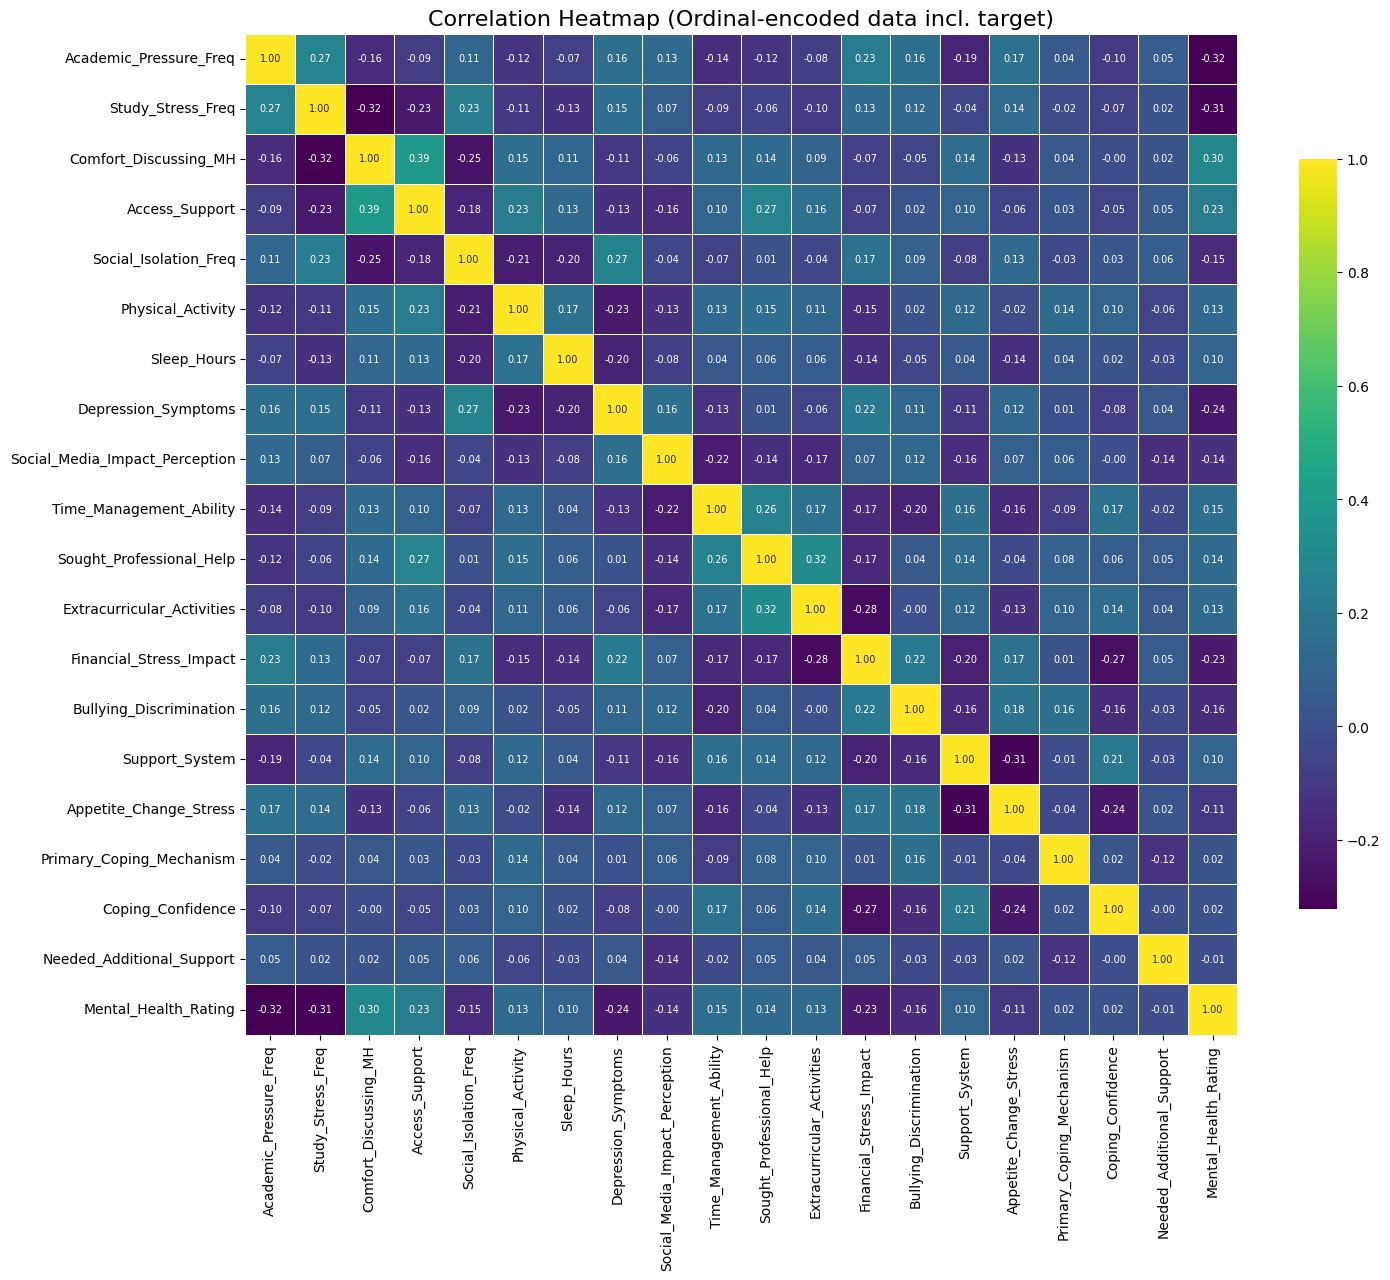

In [45]:
plt.figure(figsize=(16, 13))
sns.heatmap(enc_ordinal_show.corr(), annot=True, fmt='.2f', cmap='viridis', linewidths=0.5,
            cbar_kws={'shrink': 0.75}, annot_kws={'size': 7})
plt.title('Correlation Heatmap (Ordinal-encoded data incl. target)', fontsize=16)
plt.show()

### How much does each encoding "see" of the target?
Pearson correlation between every encoded column and the target. This is a quick measure of how much linear signal each representation exposes.

In [46]:
rows = []
for k, E in ENC_DATA.items():
    c = E.corrwith(y_all).abs()
    rows.append({'encoder': k, 'n_columns': E.shape[1], 'mean |corr| with target': c.mean(),
                 'max |corr| with target': c.max(), 'strongest column': c.idxmax()})
pd.DataFrame(rows).set_index('encoder').round(4)

,n_columns,mean |corr| with target,max |corr| with target,strongest column
encoder,,,,
Label,19,0.0943,0.2410,Academic_Pressure_Freq
One-Hot,76,0.0952,0.2808,Study_Stress_Freq_Never
Hybrid,37,0.1099,0.3225,Academic_Pressure_Freq
Ordinal,19,0.1564,0.3225,Academic_Pressure_Freq


## Step 9: Handling Class Imbalance using SMOTE
The target is not balanced (`Fair` is the largest class, `Poor` the smallest). SMOTE creates synthetic minority-class rows by interpolating between neighbouring real rows, so the model sees all classes equally often.

Two details differ from the EDA notebook, on purpose:
1. SMOTE is applied **only to the training part, after the split** (Step 12). Oversampling before the split puts synthetic copies of test rows into training and inflates scores.
2. The balancing target is "as many rows as the largest class" instead of a hard-coded 610 per class, so it works for both data versions.

`simple_smote` below is a small SMOTE (k=5 nearest neighbours, random interpolation), so the notebook runs without installing `imbalanced-learn`. On one-hot columns the interpolated values are fractions between 0 and 1; on label/ordinal codes they are in-between codes. This is a known limitation of SMOTE with categorical data.

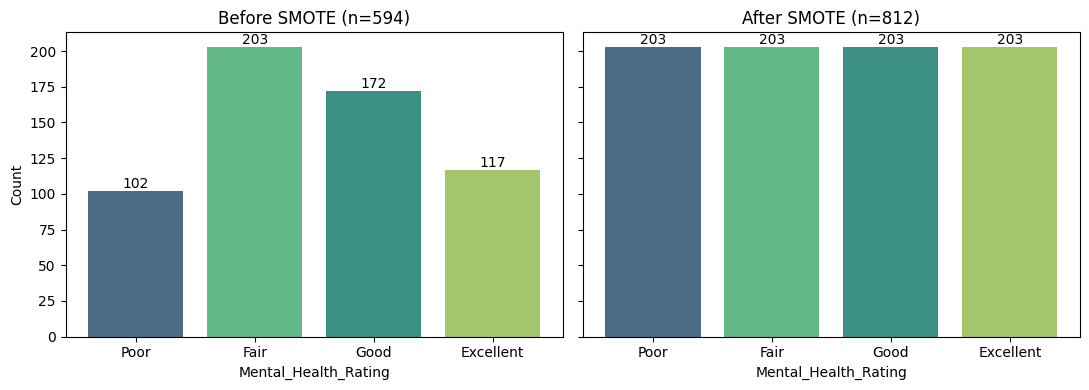

In [47]:
def simple_smote(X, y, k=5, random_state=42):
    rng = np.random.RandomState(random_state)
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    classes, counts = np.unique(y, return_counts=True)
    target = counts.max()
    Xs, ys = [X], [y]
    for c, n in zip(classes, counts):
        need = target - n
        if need <= 0:
            continue
        Xc = X[y == c]
        kk = max(1, min(k, len(Xc) - 1))
        idx = NearestNeighbors(n_neighbors=kk + 1).fit(Xc).kneighbors(Xc, return_distance=False)[:, 1:]
        base = rng.randint(0, len(Xc), need)
        nbr = idx[base, rng.randint(0, kk, need)]
        gap = rng.rand(need, 1)
        Xs.append(Xc[base] + gap * (Xc[nbr] - Xc[base]))
        ys.append(np.full(need, c))
    return np.vstack(Xs), np.concatenate(ys)

# Demonstration on the label-encoded, de-duplicated data (display only)
y_uni = df_uni[TARGET].map(target_map)
X_uni_lab = make_encoder('Label').fit_transform(df_uni[FEATURES])
Xb, yb = simple_smote(X_uni_lab.values, y_uni.values)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
before = y_uni.value_counts().sort_index(); after = pd.Series(yb).value_counts().sort_index()
for a, s, t in zip(ax, [before, after], ['Before SMOTE', 'After SMOTE']):
    a.bar(TARGET_ORDER, s.values, color=['#4c6b85', '#63b988', '#3b8f84', '#a3c56c'])
    a.set_title(f'{t} (n={s.sum()})'); a.set_xlabel('Mental_Health_Rating')
    for i, v in enumerate(s.values): a.text(i, v + 2, str(v), ha='center')
ax[0].set_ylabel('Count')
plt.tight_layout(); plt.show()

## Step 10: Selecting Features
Recursive Feature Elimination (RFE), as in the EDA notebook, ranks the label-encoded features by importance for the (SMOTE-balanced) target.

All 19 features are **kept** for the experiments. If each encoder used a different feature subset, we could no longer tell whether a score difference came from the *encoding* or from the *features*.

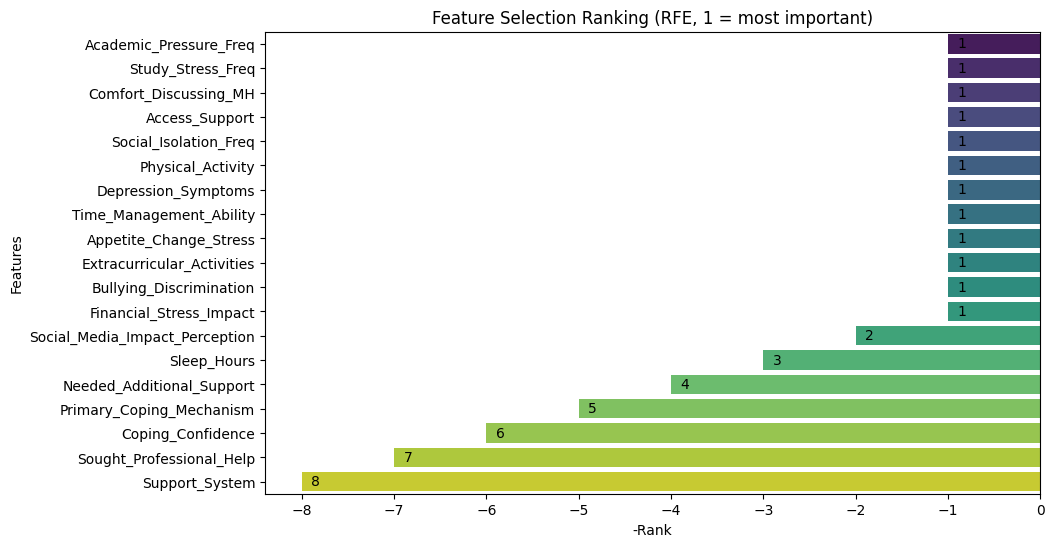

Top 12 features by RFE: ['Academic_Pressure_Freq', 'Study_Stress_Freq', 'Comfort_Discussing_MH', 'Access_Support', 'Social_Isolation_Freq', 'Physical_Activity', 'Depression_Symptoms', 'Time_Management_Ability', 'Appetite_Change_Stress', 'Extracurricular_Activities', 'Bullying_Discrimination', 'Financial_Stress_Impact']


In [48]:
Xr = pd.DataFrame(Xb, columns=FEATURES)
rfe = RFE(LinearRegression(), n_features_to_select=12).fit(Xr, yb)
rfe_ranking = pd.Series(rfe.ranking_, index=FEATURES).sort_values()

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=-rfe_ranking, y=rfe_ranking.index, palette='viridis')
for i, v in enumerate(-rfe_ranking):
    ax.text(v + 0.1, i, f'{abs(v)}', va='center')
plt.title('Feature Selection Ranking (RFE, 1 = most important)')
plt.xlabel('-Rank'); plt.ylabel('Features')
plt.show()
print('Top 12 features by RFE:', list(rfe_ranking.index[:12]))

## Step 11: Splitting the Dataset
Stratified 80/20 split (class proportions kept equal in train and test), done for both versions of the cleaned data.

The **leakage check** counts test rows that also appear, identically, in the training set.

In [49]:
def make_split(data, seed=42):
    X, y = data[FEATURES], data[TARGET].map(target_map)
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

for name, data in [('df_dup (duplicates kept)', df_dup), ('df_uni (de-duplicated)', df_uni)]:
    Xtr, Xte, ytr, yte = make_split(data)
    train_keys = set(map(tuple, Xtr.values))
    leaked = sum(tuple(r) in train_keys for r in Xte.values)
    print(f'{name:26s} train={len(Xtr):5d} test={len(Xte):4d} | test rows that also exist in train: {leaked} ({leaked/len(Xte):.1%})')

df_dup (duplicates kept)   train= 1359 test= 340 | test rows that also exist in train: 314 (92.4%)
df_uni (de-duplicated)     train=  475 test= 119 | test rows that also exist in train: 0 (0.0%)


With duplicates kept, most test rows have an identical twin in the training data. A model that memorises the training set will score very high without learning anything general. This is why `df_uni` gives the honest evaluation.

## Step 12: Model Pipeline and Evaluation
For every **encoder** (Label, One-Hot, Hybrid, Ordinal) we train every **model** (Decision Tree, KNN, MLP) on the identical split. Model settings are fixed and identical for all encoders, so the encoder is the only thing that changes.

| Model | Settings | Scaling |
|---|---|---|
| Decision Tree | `max_depth=8` | none (trees do not need it) |
| KNN | `n_neighbors=7` | `StandardScaler` |
| MLP (neural network) | hidden layers `(64, 32)`, `max_iter=500` | `StandardScaler` |

Metrics on the untouched test split: accuracy, macro precision, macro recall, macro F1 (macro = every class counts equally). Because one split is noisy on small data, we also report **5-fold x 3-repeat cross-validation** (mean ± std), where the whole pipeline (encode, SMOTE, scale, fit) is re-run inside each fold.

In [50]:
MODELS = ['Decision Tree', 'KNN', 'MLP']

def build_model(name):
    if name == 'Decision Tree':
        return DecisionTreeClassifier(max_depth=8, random_state=42)
    if name == 'KNN':
        return Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=7))])
    if name == 'MLP':
        return Pipeline([('scale', StandardScaler()),
                         ('clf', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))])

def fit_predict(enc_name, model_name, Xtr, ytr, Xte):
    enc = make_encoder(enc_name).fit(Xtr)                       # 1. encode
    Etr, Ete = enc.transform(Xtr), enc.transform(Xte)
    Eb, yb = simple_smote(Etr.values, ytr.values)               # 2. SMOTE on train only
    model = build_model(model_name).fit(Eb, yb)                 # 3. scale + fit
    return model.predict(Ete.values)

def cv_scores(data, enc_name, model_name):
    X, y = data[FEATURES], data[TARGET].map(target_map)
    acc, f1 = [], []
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(X, y):
        p = fit_predict(enc_name, model_name, X.iloc[tr], y.iloc[tr], X.iloc[te])
        acc.append(accuracy_score(y.iloc[te], p)); f1.append(f1_score(y.iloc[te], p, average='macro'))
    return np.array(acc), np.array(f1)

PERCLASS = []   # per-class precision / recall / F1 for every encoder + model (used for the tables below)

def evaluate_protocol(data, tag, show_reports):
    Xtr, Xte, ytr, yte = make_split(data)
    base = (yte == ytr.mode()[0]).mean()
    print(f'[{tag}] train={len(Xtr)}, test={len(Xte)} | majority-class baseline accuracy = {base:.3f} | random guess = 0.250\n')
    rows, preds = [], {}
    for enc in ENCODERS:
        if show_reports:
            print('=' * 78); print(f'ENCODER: {enc}   ({make_encoder(enc).fit(Xtr).transform(Xtr).shape[1]} input columns)'); print('=' * 78)
        cms = {}
        for mod in MODELS:
            p = fit_predict(enc, mod, Xtr, ytr, Xte)
            preds[f'{enc} | {mod}'] = p
            cms[mod] = confusion_matrix(yte, p, labels=[0, 1, 2, 3])
            if show_reports:
                pr, rc, f1c, _ = precision_recall_fscore_support(yte, p, labels=[0, 1, 2, 3], zero_division=0)
                for ci, cname in enumerate(TARGET_ORDER):
                    PERCLASS.append(dict(protocol=tag, encoder=enc, model=mod, cls=f'{ci} ({cname})',
                                         precision=pr[ci], recall=rc[ci], f1=f1c[ci]))
            cva, cvf = cv_scores(data, enc, mod)
            r = dict(encoder=enc, model=mod,
                     accuracy=accuracy_score(yte, p),
                     precision=precision_score(yte, p, average='macro', zero_division=0),
                     recall=recall_score(yte, p, average='macro', zero_division=0),
                     f1_macro=f1_score(yte, p, average='macro'),
                     cv_acc=cva.mean(), cv_acc_std=cva.std(), cv_f1=cvf.mean(), cv_f1_std=cvf.std())
            rows.append(r)
            if show_reports:
                print(f'Encoder: {enc}')
                print(f'Model: {mod}')
                print(f"Accuracy: {r['accuracy']:.4f}")
                print(classification_report(yte, p, labels=[0, 1, 2, 3], target_names=TARGET_ORDER, zero_division=0))
                print(f'Mean Squared Error: {np.mean((yte.values - p) ** 2):.4f}')
                print('Sensitivity (Recall) for each class:', recall_score(yte, p, labels=[0, 1, 2, 3], average=None, zero_division=0).round(4))
                print(f"CV (5x3) : accuracy={r['cv_acc']:.3f} ± {r['cv_acc_std']:.3f}   macro-F1={r['cv_f1']:.3f} ± {r['cv_f1_std']:.3f}")
                print('-' * 78)
            else:
                print(f"{enc:8s} + {mod:13s}: hold-out acc={r['accuracy']:.3f}  macro-F1={r['f1_macro']:.3f} | CV acc={r['cv_acc']:.3f} ± {r['cv_acc_std']:.3f}")
        if show_reports:
            fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
            for ax, mod in zip(axes, MODELS):
                sns.heatmap(cms[mod], annot=True, fmt='d', cmap='viridis', ax=ax,
                            xticklabels=TARGET_ORDER, yticklabels=TARGET_ORDER)
                ax.set_title(f'Confusion Matrix: {mod} ({enc} encoding)', fontsize=10)
                ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
            plt.tight_layout(); plt.show()
    return pd.DataFrame(rows), pd.DataFrame(preds, index=yte.index), yte, Xte

print('Pipeline functions ready.')

Pipeline functions ready.


### 12.1 Honest evaluation: de-duplicated data (`df_uni`)
Full report for every encoder + model combination.

[df_uni, de-duplicated] train=475, test=119 | majority-class baseline accuracy = 0.345 | random guess = 0.250

ENCODER: Label   (19 input columns)
Encoder: Label
Model: Decision Tree
Accuracy: 0.3613
              precision    recall  f1-score   support

        Poor       0.21      0.30      0.24        20
        Fair       0.40      0.29      0.34        41
        Good       0.42      0.46      0.44        35
   Excellent       0.41      0.39      0.40        23

    accuracy                           0.36       119
   macro avg       0.36      0.36      0.36       119
weighted avg       0.38      0.36      0.36       119

Mean Squared Error: 1.8319
Sensitivity (Recall) for each class: [0.3    0.2927 0.4571 0.3913]
CV (5x3) : accuracy=0.367 ± 0.047   macro-F1=0.350 ± 0.045
------------------------------------------------------------------------------
Encoder: Label
Model: KNN
Accuracy: 0.3445
              precision    recall  f1-score   support

        Poor       0.30      0.50  

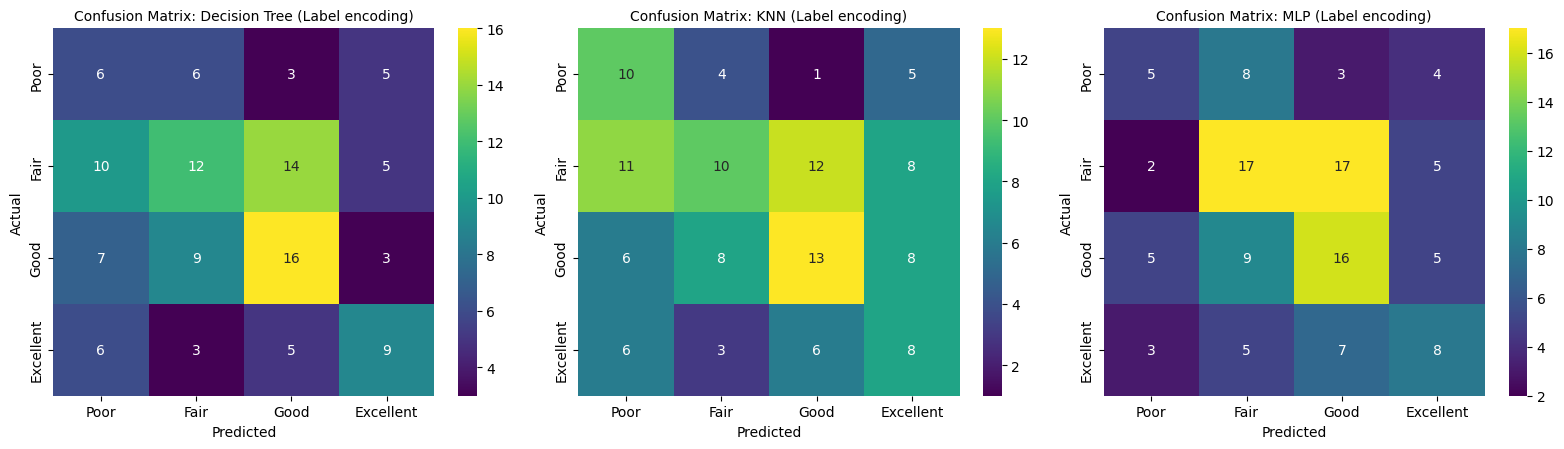

ENCODER: One-Hot   (76 input columns)
Encoder: One-Hot
Model: Decision Tree
Accuracy: 0.3529
              precision    recall  f1-score   support

        Poor       0.21      0.30      0.24        20
        Fair       0.54      0.32      0.40        41
        Good       0.35      0.40      0.37        35
   Excellent       0.35      0.39      0.37        23

    accuracy                           0.35       119
   macro avg       0.36      0.35      0.35       119
weighted avg       0.39      0.35      0.36       119

Mean Squared Error: 1.7647
Sensitivity (Recall) for each class: [0.3    0.3171 0.4    0.3913]
CV (5x3) : accuracy=0.377 ± 0.038   macro-F1=0.361 ± 0.037
------------------------------------------------------------------------------
Encoder: One-Hot
Model: KNN
Accuracy: 0.4118
              precision    recall  f1-score   support

        Poor       0.33      0.80      0.46        20
        Fair       0.58      0.17      0.26        41
        Good       0.39      0.3

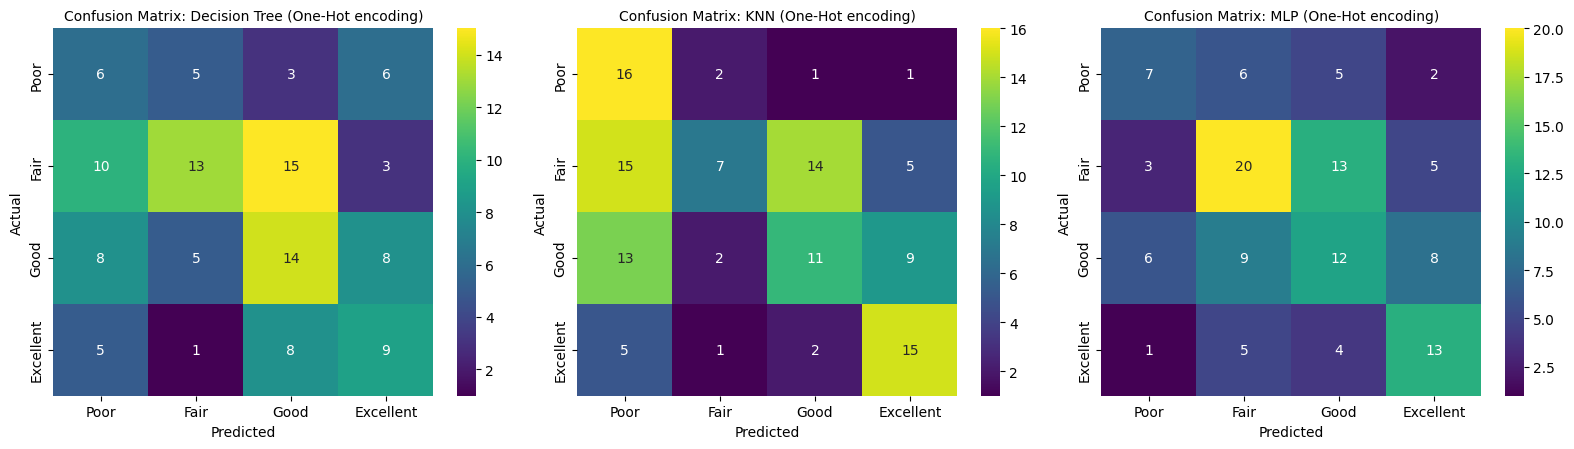

ENCODER: Hybrid   (37 input columns)
Encoder: Hybrid
Model: Decision Tree
Accuracy: 0.3697
              precision    recall  f1-score   support

        Poor       0.26      0.25      0.26        20
        Fair       0.39      0.32      0.35        41
        Good       0.35      0.43      0.38        35
   Excellent       0.46      0.48      0.47        23

    accuracy                           0.37       119
   macro avg       0.37      0.37      0.37       119
weighted avg       0.37      0.37      0.37       119

Mean Squared Error: 1.3361
Sensitivity (Recall) for each class: [0.25   0.3171 0.4286 0.4783]
CV (5x3) : accuracy=0.361 ± 0.042   macro-F1=0.342 ± 0.047
------------------------------------------------------------------------------
Encoder: Hybrid
Model: KNN
Accuracy: 0.3782
              precision    recall  f1-score   support

        Poor       0.29      0.50      0.36        20
        Fair       0.30      0.17      0.22        41
        Good       0.47      0.43  

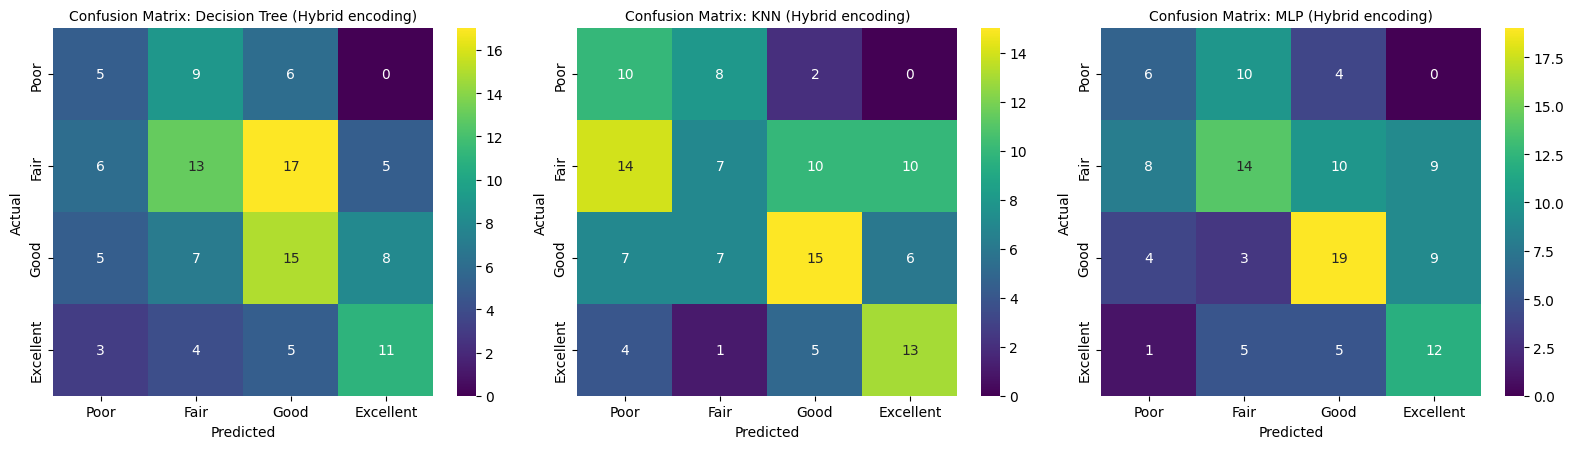

ENCODER: Ordinal   (19 input columns)
Encoder: Ordinal
Model: Decision Tree
Accuracy: 0.4370
              precision    recall  f1-score   support

        Poor       0.37      0.35      0.36        20
        Fair       0.43      0.59      0.49        41
        Good       0.57      0.37      0.45        35
   Excellent       0.38      0.35      0.36        23

    accuracy                           0.44       119
   macro avg       0.44      0.41      0.42       119
weighted avg       0.45      0.44      0.43       119

Mean Squared Error: 1.3697
Sensitivity (Recall) for each class: [0.35   0.5854 0.3714 0.3478]
CV (5x3) : accuracy=0.376 ± 0.044   macro-F1=0.360 ± 0.043
------------------------------------------------------------------------------
Encoder: Ordinal
Model: KNN
Accuracy: 0.3866
              precision    recall  f1-score   support

        Poor       0.25      0.40      0.31        20
        Fair       0.38      0.32      0.35        41
        Good       0.50      0.4

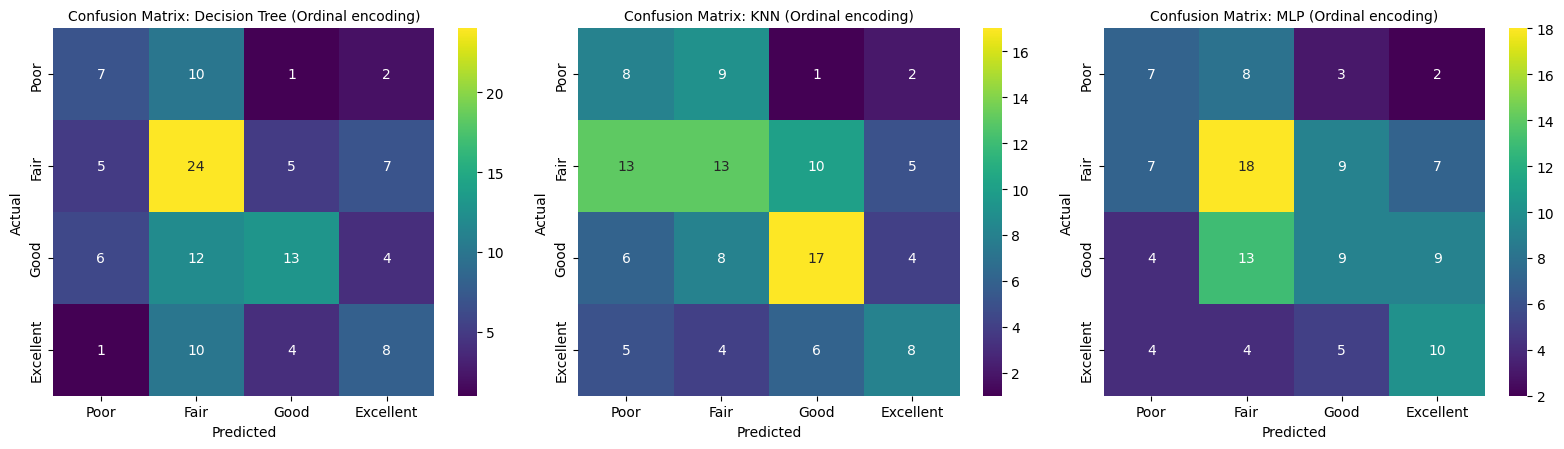

In [51]:
res_uni, pred_uni, yte_uni, Xte_uni = evaluate_protocol(df_uni, 'df_uni, de-duplicated', show_reports=True)

### 12.2 Naive evaluation: duplicates kept (`df_dup`)
Same pipeline on the data with duplicates. Compact output only. Compare these numbers with 12.1 to see how much memorisation inflates the scores.

In [52]:
res_dup, pred_dup, yte_dup, Xte_dup = evaluate_protocol(df_dup, 'df_dup, duplicates kept', show_reports=False)

[df_dup, duplicates kept] train=1359, test=340 | majority-class baseline accuracy = 0.335 | random guess = 0.250

Label    + Decision Tree: hold-out acc=0.709  macro-F1=0.709 | CV acc=0.714 ± 0.022
Label    + KNN          : hold-out acc=0.574  macro-F1=0.577 | CV acc=0.552 ± 0.024
Label    + MLP          : hold-out acc=0.965  macro-F1=0.963 | CV acc=0.967 ± 0.015
One-Hot  + Decision Tree: hold-out acc=0.656  macro-F1=0.661 | CV acc=0.676 ± 0.030
One-Hot  + KNN          : hold-out acc=0.571  macro-F1=0.573 | CV acc=0.596 ± 0.030
One-Hot  + MLP          : hold-out acc=0.959  macro-F1=0.957 | CV acc=0.974 ± 0.011
Hybrid   + Decision Tree: hold-out acc=0.682  macro-F1=0.679 | CV acc=0.696 ± 0.049
Hybrid   + KNN          : hold-out acc=0.550  macro-F1=0.553 | CV acc=0.578 ± 0.012
Hybrid   + MLP          : hold-out acc=0.947  macro-F1=0.941 | CV acc=0.965 ± 0.020
Ordinal  + Decision Tree: hold-out acc=0.726  macro-F1=0.723 | CV acc=0.693 ± 0.049
Ordinal  + KNN          : hold-out acc=0.606  

## Step 13: Results: Which Encoding Works with Which Model?

### 13.1 Encoder x Model result tables (de-duplicated data, the honest result)

In [53]:
def matrix(res, col):
    return res.pivot(index='encoder', columns='model', values=col).loc[ENCODERS, MODELS]

print('HOLD-OUT ACCURACY'); print(matrix(res_uni, 'accuracy').round(3), '\n')
print('HOLD-OUT MACRO-F1'); print(matrix(res_uni, 'f1_macro').round(3), '\n')
print('CROSS-VALIDATED ACCURACY (mean of 15 folds)'); print(matrix(res_uni, 'cv_acc').round(3), '\n')
print('CROSS-VALIDATED ACCURACY (std of 15 folds)');  print(matrix(res_uni, 'cv_acc_std').round(3))

HOLD-OUT ACCURACY
model    Decision Tree    KNN    MLP
encoder                             
Label            0.361  0.345  0.387
One-Hot          0.353  0.412  0.437
Hybrid           0.370  0.378  0.429
Ordinal          0.437  0.387  0.370 

HOLD-OUT MACRO-F1
model    Decision Tree    KNN    MLP
encoder                             
Label            0.355  0.344  0.369
One-Hot          0.346  0.411  0.432
Hybrid           0.365  0.383  0.416
Ordinal          0.416  0.382  0.362 

CROSS-VALIDATED ACCURACY (mean of 15 folds)
model    Decision Tree    KNN    MLP
encoder                             
Label            0.367  0.339  0.367
One-Hot          0.377  0.363  0.410
Hybrid           0.361  0.348  0.356
Ordinal          0.376  0.366  0.388 

CROSS-VALIDATED ACCURACY (std of 15 folds)
model    Decision Tree    KNN    MLP
encoder                             
Label            0.047  0.037  0.028
One-Hot          0.038  0.026  0.033
Hybrid           0.042  0.047  0.040
Ordinal          0.0

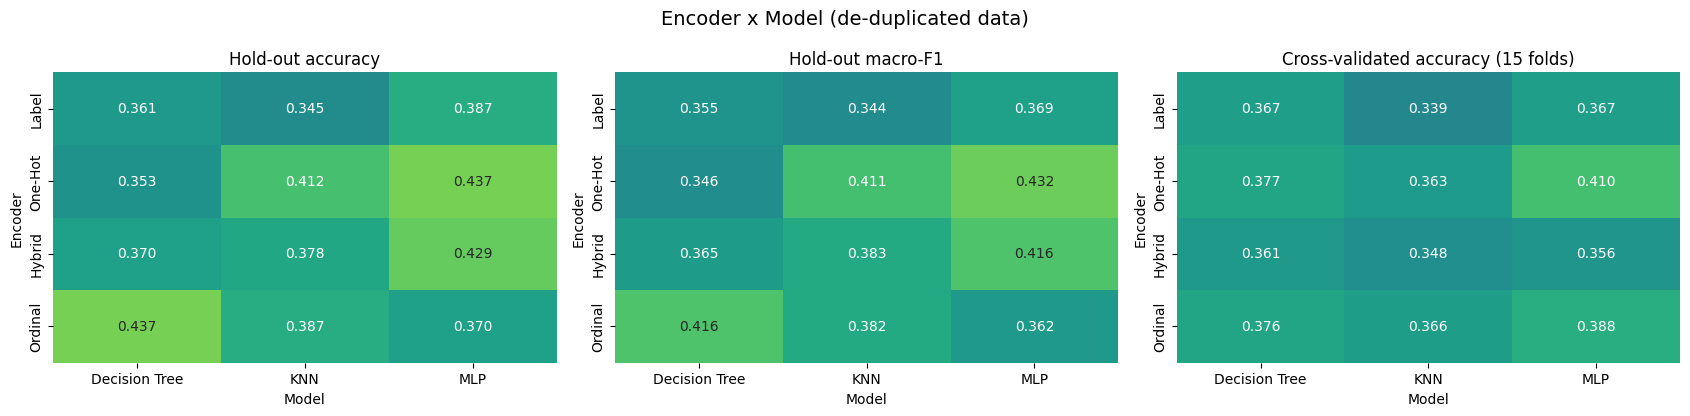

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (col, title) in zip(axes, [('accuracy', 'Hold-out accuracy'), ('f1_macro', 'Hold-out macro-F1'),
                                    ('cv_acc', 'Cross-validated accuracy (15 folds)')]):
    sns.heatmap(matrix(res_uni, col), annot=True, fmt='.3f', cmap='viridis', vmin=0.2, vmax=0.5, ax=ax, cbar=False)
    ax.set_title(title); ax.set_xlabel('Model'); ax.set_ylabel('Encoder')
plt.suptitle('Encoder x Model (de-duplicated data)', fontsize=14); plt.tight_layout(); plt.show()

### 13.2 The answers each combination gives
Beyond accuracy: *what does each combination actually predict?* The table shows the percentage of test rows that each encoder + model assigned to every rating, against the true distribution. A model that puts almost everything into one class is not really discriminating.

In [55]:
true_dist = (yte_uni.map(dict(enumerate(TARGET_ORDER))).value_counts(normalize=True)[TARGET_ORDER] * 100).round(1)
dist = pred_uni.apply(lambda s: s.map(dict(enumerate(TARGET_ORDER))).value_counts(normalize=True).reindex(TARGET_ORDER).fillna(0) * 100).T.round(1)
dist.loc['TRUE distribution'] = true_dist
dist.columns = [f'% predicted {c}' for c in TARGET_ORDER]
dist

,% predicted Poor,% predicted Fair,% predicted Good,% predicted Excellent
Label | Decision Tree,24.4,25.2,31.9,18.5
Label | KNN,27.7,21.0,26.9,24.4
Label | MLP,12.6,32.8,36.1,18.5
One-Hot | Decision Tree,24.4,20.2,33.6,21.8
One-Hot | KNN,41.2,10.1,23.5,25.2
One-Hot | MLP,14.3,33.6,28.6,23.5
Hybrid | Decision Tree,16.0,27.7,36.1,20.2
Hybrid | KNN,29.4,19.3,26.9,24.4
Hybrid | MLP,16.0,26.9,31.9,25.2
Ordinal | Decision Tree,16.0,47.1,19.3,17.6


In [56]:
# Per-class recall: how many of the TRUE Poor / Fair / Good / Excellent rows does each combination find?
rec = {}
for k, p in pred_uni.items():
    rec[k] = recall_score(yte_uni, p, labels=[0, 1, 2, 3], average=None, zero_division=0)
pd.DataFrame(rec, index=[f'recall {c}' for c in TARGET_ORDER]).T.round(2)

,recall Poor,recall Fair,recall Good,recall Excellent
Label | Decision Tree,0.30,0.29,0.46,0.39
Label | KNN,0.50,0.24,0.37,0.35
Label | MLP,0.25,0.41,0.46,0.35
One-Hot | Decision Tree,0.30,0.32,0.40,0.39
One-Hot | KNN,0.80,0.17,0.31,0.65
One-Hot | MLP,0.35,0.49,0.34,0.57
Hybrid | Decision Tree,0.25,0.32,0.43,0.48
Hybrid | KNN,0.50,0.17,0.43,0.57
Hybrid | MLP,0.30,0.34,0.54,0.52
Ordinal | Decision Tree,0.35,0.59,0.37,0.35


In [57]:
# One combined table: encoder x model, each cell = accuracy / macro-F1 / most frequent answer
cells = {}
for _, r in res_uni.iterrows():
    top = pred_uni[f"{r['encoder']} | {r['model']}"].map(dict(enumerate(TARGET_ORDER))).value_counts().idxmax()
    cells[(r['encoder'], r['model'])] = f"acc {r['accuracy']:.2f} | F1 {r['f1_macro']:.2f} | mostly '{top}'"
combined = pd.Series(cells).unstack()[MODELS].loc[ENCODERS]
pd.set_option('display.max_colwidth', 60)
print(combined.to_string())
pd.set_option('display.max_colwidth', 40)

                              Decision Tree                                 KNN                                 MLP
Label    acc 0.36 | F1 0.36 | mostly 'Good'  acc 0.34 | F1 0.34 | mostly 'Poor'  acc 0.39 | F1 0.37 | mostly 'Good'
One-Hot  acc 0.35 | F1 0.35 | mostly 'Good'  acc 0.41 | F1 0.41 | mostly 'Poor'  acc 0.44 | F1 0.43 | mostly 'Fair'
Hybrid   acc 0.37 | F1 0.37 | mostly 'Good'  acc 0.38 | F1 0.38 | mostly 'Poor'  acc 0.43 | F1 0.42 | mostly 'Good'
Ordinal  acc 0.44 | F1 0.42 | mostly 'Fair'  acc 0.39 | F1 0.38 | mostly 'Good'  acc 0.37 | F1 0.36 | mostly 'Fair'


In [58]:
# Sample of actual predictions: the first 12 test rows, true rating vs the 12 combinations' answers
inv = dict(enumerate(TARGET_ORDER))
sample = pred_uni.head(12).apply(lambda s: s.map(inv))
sample.insert(0, 'TRUE', yte_uni.loc[sample.index].map(inv))
sample.columns = [c.replace(' | ', '\n') for c in sample.columns]
print(sample.to_string())

          TRUE Label\nDecision Tree Label\nKNN Label\nMLP One-Hot\nDecision Tree One-Hot\nKNN One-Hot\nMLP Hybrid\nDecision Tree Hybrid\nKNN Hybrid\nMLP Ordinal\nDecision Tree Ordinal\nKNN Ordinal\nMLP
541  Excellent                 Poor  Excellent  Excellent                   Good    Excellent    Excellent                  Good   Excellent        Fair                   Fair         Poor    Excellent
59        Fair                 Good       Poor       Good                   Fair         Poor         Fair                  Fair        Poor        Fair                   Fair         Poor         Poor
500       Good            Excellent  Excellent       Good                   Good    Excellent         Fair             Excellent   Excellent        Good              Excellent    Excellent    Excellent
237       Poor                 Fair       Poor       Fair                   Poor         Poor         Poor                  Fair        Poor        Fair                   Fair         Fair    

### 13.3 Duplicates inflate the score
Cross-validated accuracy for the same 12 combinations, with duplicates kept (`df_dup`) versus removed (`df_uni`).

                       df_dup CV acc  df_uni CV acc  inflation
encoder model                                                 
Label   Decision Tree          0.714          0.367      0.347
        KNN                    0.552          0.339      0.213
        MLP                    0.967          0.367      0.600
One-Hot Decision Tree          0.676          0.377      0.299
        KNN                    0.596          0.363      0.233
        MLP                    0.974          0.410      0.563
Hybrid  Decision Tree          0.696          0.361      0.335
        KNN                    0.578          0.348      0.230
        MLP                    0.965          0.356      0.608
Ordinal Decision Tree          0.693          0.376      0.317
        KNN                    0.616          0.366      0.250
        MLP                    0.964          0.388      0.577


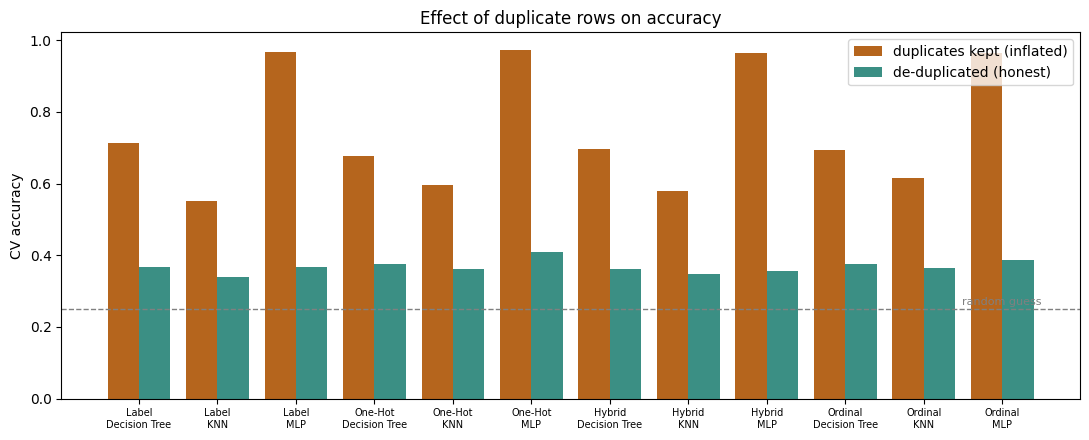

In [59]:
cmp = pd.DataFrame({'df_dup CV acc': matrix(res_dup, 'cv_acc').stack(), 'df_uni CV acc': matrix(res_uni, 'cv_acc').stack()})
cmp['inflation'] = cmp['df_dup CV acc'] - cmp['df_uni CV acc']
print(cmp.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
labels = [f'{e}\n{m}' for e, m in cmp.index]
x = np.arange(len(labels)); w = 0.4
ax.bar(x - w/2, cmp['df_dup CV acc'], w, label='duplicates kept (inflated)', color='#b5651d')
ax.bar(x + w/2, cmp['df_uni CV acc'], w, label='de-duplicated (honest)', color='#3b8f84')
ax.axhline(0.25, ls='--', c='grey', lw=1); ax.text(len(x) - 0.5, 0.26, 'random guess', ha='right', fontsize=8, color='grey')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7); ax.set_ylabel('CV accuracy'); ax.legend()
ax.set_title('Effect of duplicate rows on accuracy'); plt.tight_layout(); plt.show()

### 13.4 Per-class results tables (same layout as the lab report)
Model / Class / Precision / Recall / F1-score for every encoder, on the de-duplicated test set.

In [60]:
pc = pd.DataFrame(PERCLASS)
pc = pc[pc.protocol.str.startswith('df_uni')]
for enc in ENCODERS:
    print(f'Results of {enc} Encoding')
    t = pc[pc.encoder == enc][['model', 'cls', 'precision', 'recall', 'f1']].round(2)
    t.columns = ['Model', 'Class', 'Precision', 'Recall', 'F1-score']
    print(t.to_string(index=False)); print()

Results of Label Encoding
        Model         Class  Precision  Recall  F1-score
Decision Tree      0 (Poor)       0.21    0.30      0.24
Decision Tree      1 (Fair)       0.40    0.29      0.34
Decision Tree      2 (Good)       0.42    0.46      0.44
Decision Tree 3 (Excellent)       0.41    0.39      0.40
          KNN      0 (Poor)       0.30    0.50      0.38
          KNN      1 (Fair)       0.40    0.24      0.30
          KNN      2 (Good)       0.41    0.37      0.39
          KNN 3 (Excellent)       0.28    0.35      0.31
          MLP      0 (Poor)       0.33    0.25      0.29
          MLP      1 (Fair)       0.44    0.41      0.42
          MLP      2 (Good)       0.37    0.46      0.41
          MLP 3 (Excellent)       0.36    0.35      0.36

Results of One-Hot Encoding
        Model         Class  Precision  Recall  F1-score
Decision Tree      0 (Poor)       0.21    0.30      0.24
Decision Tree      1 (Fair)       0.54    0.32      0.40
Decision Tree      2 (Good)      

In [61]:
# Final result: macro-average F1 (average of the four class-level F1 scores) by encoding method and model
macro = pc.groupby(['encoder', 'model'])['f1'].mean().unstack()[MODELS].loc[ENCODERS]
macro['Average across models'] = macro.mean(axis=1)
macro.round(3)

model,Decision Tree,KNN,MLP,Average across models
encoder,,,,
Label,0.355,0.344,0.369,0.356
One-Hot,0.346,0.411,0.432,0.397
Hybrid,0.365,0.383,0.416,0.388
Ordinal,0.416,0.382,0.362,0.387


## Step 14: Correlation Tables: 4 Encoders x 3 Models
Each of the 12 encoder + model combinations produces one answer (a predicted rating) for every test row. The correlation between two combinations' answer columns tells us **how similarly they behave**:

- close to **1**: they predict nearly the same ratings for the same people
- close to **0**: their answers are unrelated
- `NaN`: one of them predicts a single class for everyone (zero variance, correlation undefined)

The first table adds the true rating as a reference row/column, so the `TRUE` row shows which combination correlates best with reality.

In [62]:
def corr_table(preds, y_true):
    P = preds.copy(); P.insert(0, 'TRUE', y_true.values)
    return P.corr()

corr_uni = corr_table(pred_uni, yte_uni)
print('Correlation of answers (de-duplicated data, test set):')
corr_uni.round(2)

Correlation of answers (de-duplicated data, test set):


,TRUE,Label | Decision Tree,Label | KNN,Label | MLP,One-Hot | Decision Tree,One-Hot | KNN,One-Hot | MLP,Hybrid | Decision Tree,Hybrid | KNN,Hybrid | MLP,Ordinal | Decision Tree,Ordinal | KNN,Ordinal | MLP
TRUE,1.00,0.12,0.19,0.17,0.18,0.43,0.35,0.31,0.40,0.42,0.28,0.29,0.28
Label | Decision Tree,0.12,1.00,0.40,0.28,0.29,0.19,0.23,0.41,0.24,0.22,0.30,0.25,0.16
Label | KNN,0.19,0.40,1.00,0.54,0.32,0.32,0.39,0.26,0.33,0.41,0.33,0.41,0.28
Label | MLP,0.17,0.28,0.54,1.00,0.08,0.29,0.27,0.28,0.19,0.23,0.13,0.28,0.25
One-Hot | Decision Tree,0.18,0.29,0.32,0.08,1.00,0.22,0.30,0.23,0.31,0.28,0.22,0.28,0.31
One-Hot | KNN,0.43,0.19,0.32,0.29,0.22,1.00,0.47,0.38,0.54,0.46,0.40,0.45,0.48
One-Hot | MLP,0.35,0.23,0.39,0.27,0.30,0.47,1.00,0.45,0.50,0.52,0.40,0.43,0.52
Hybrid | Decision Tree,0.31,0.41,0.26,0.28,0.23,0.38,0.45,1.00,0.38,0.40,0.39,0.45,0.55
Hybrid | KNN,0.40,0.24,0.33,0.19,0.31,0.54,0.50,0.38,1.00,0.49,0.47,0.52,0.35
Hybrid | MLP,0.42,0.22,0.41,0.23,0.28,0.46,0.52,0.40,0.49,1.00,0.36,0.39,0.37


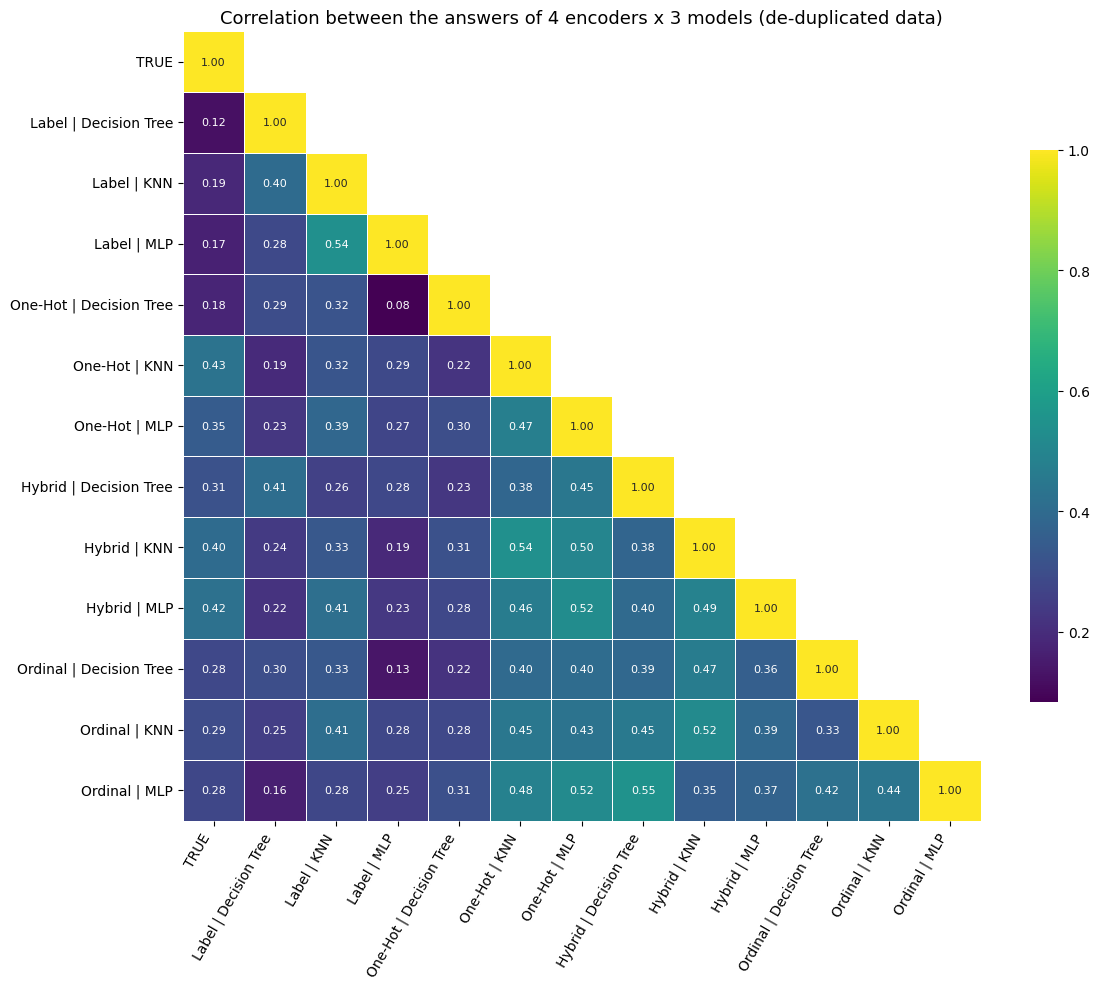

In [63]:
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_uni, dtype=bool), k=1)
sns.heatmap(corr_uni, annot=True, fmt='.2f', cmap='viridis', mask=mask, linewidths=0.5,
            cbar_kws={'shrink': 0.7}, annot_kws={'size': 8})
plt.title('Correlation between the answers of 4 encoders x 3 models (de-duplicated data)', fontsize=13)
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

Correlation of predicted rating with TRUE rating (4 encoders x 3 models):
model    Decision Tree    KNN    MLP
encoder                             
Label            0.120  0.186  0.166
One-Hot          0.179  0.432  0.347
Hybrid           0.314  0.398  0.421
Ordinal          0.281  0.291  0.279


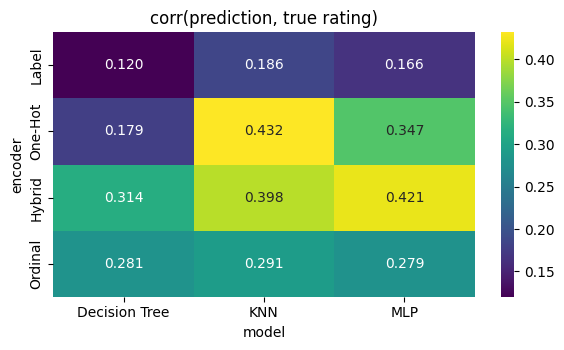

In [64]:
# Compact view: correlation of each combination's answer with the TRUE rating (4 x 3)
true_corr = corr_uni['TRUE'].drop('TRUE')
tc = pd.DataFrame([(k.split(' | ')[0], k.split(' | ')[1], v) for k, v in true_corr.items()],
                  columns=['encoder', 'model', 'corr']).pivot(index='encoder', columns='model', values='corr').loc[ENCODERS, MODELS]
print('Correlation of predicted rating with TRUE rating (4 encoders x 3 models):'); print(tc.round(3))
plt.figure(figsize=(6, 3.6))
sns.heatmap(tc, annot=True, fmt='.3f', cmap='viridis'); plt.title('corr(prediction, true rating)'); plt.tight_layout(); plt.show()

In [65]:
# Does the encoder matter more, or the model? Average the 12 predictions' agreement within vs across groups
names_ = list(pred_uni.columns)
P = corr_uni.drop(index='TRUE', columns='TRUE')
same_model = np.nanmean([P.loc[a, b] for a in names_ for b in names_ if a < b and a.split(' | ')[1] == b.split(' | ')[1]])
same_enc   = np.nanmean([P.loc[a, b] for a in names_ for b in names_ if a < b and a.split(' | ')[0] == b.split(' | ')[0]])
print(f'Mean correlation between answers of the SAME model, different encoders : {same_model:.3f}')
print(f'Mean correlation between answers of the SAME encoder, different models : {same_enc:.3f}')

Mean correlation between answers of the SAME model, different encoders : 0.365
Mean correlation between answers of the SAME encoder, different models : 0.389


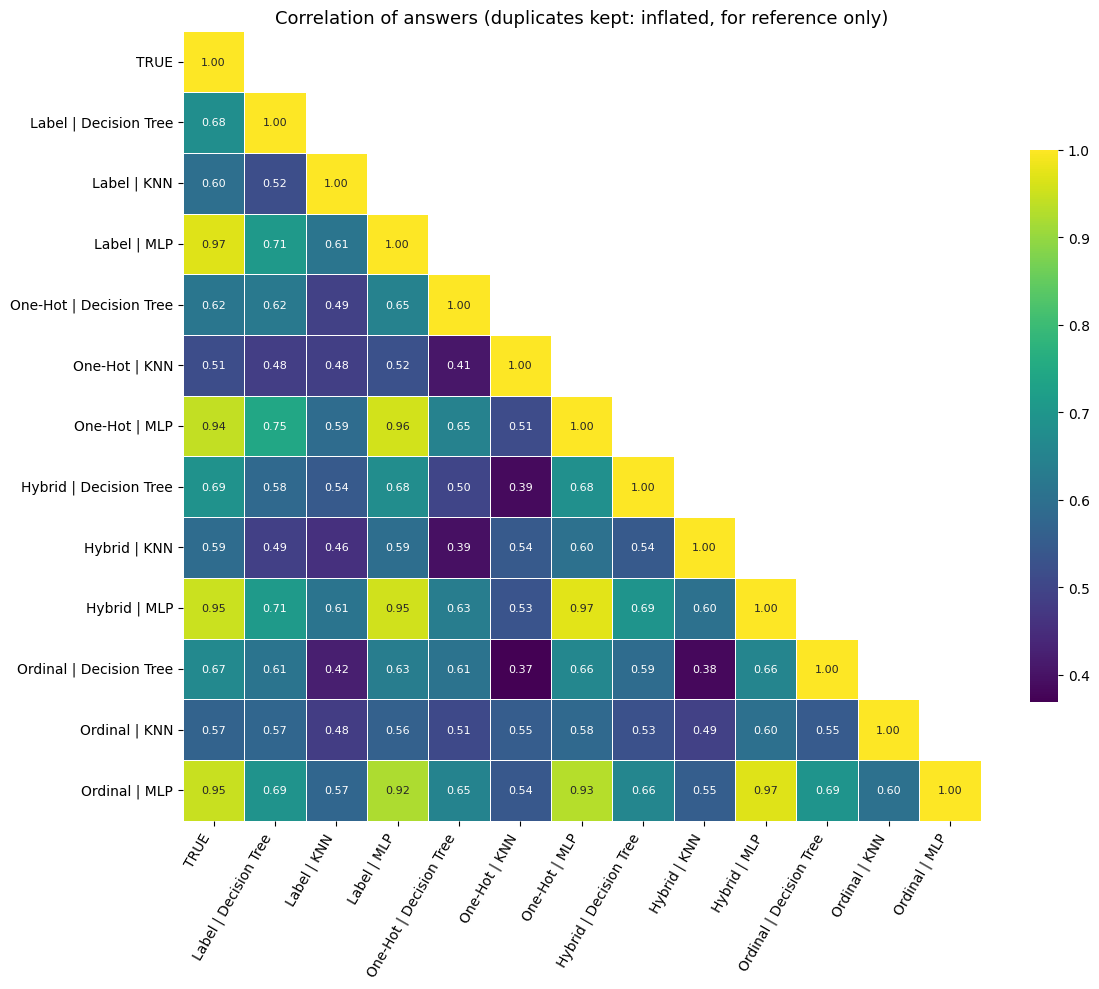

In [66]:
# Same correlation matrix for the naive data (duplicates kept), for reference
corr_dup = corr_table(pred_dup, yte_dup)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_dup, annot=True, fmt='.2f', cmap='viridis', mask=np.triu(np.ones_like(corr_dup, dtype=bool), k=1),
            linewidths=0.5, cbar_kws={'shrink': 0.7}, annot_kws={'size': 8})
plt.title('Correlation of answers (duplicates kept: inflated, for reference only)', fontsize=13)
plt.xticks(rotation=60, ha='right'); plt.tight_layout(); plt.show()

## Step 15: Summary of Results

In [67]:
best = res_uni.loc[res_uni.groupby('model')['cv_acc'].idxmax(), ['model', 'encoder', 'cv_acc', 'cv_acc_std', 'accuracy', 'f1_macro']]
print('Best encoder for each model (by cross-validated accuracy, de-duplicated data):')
print(best.round(3).to_string(index=False)); print()
bye = res_uni.loc[res_uni.groupby('encoder')['cv_acc'].idxmax(), ['encoder', 'model', 'cv_acc', 'cv_acc_std', 'accuracy', 'f1_macro']]
print('Best model for each encoder:')
print(bye.round(3).to_string(index=False)); print()
print('Average CV accuracy per encoder :'); print(res_uni.groupby('encoder')['cv_acc'].mean().loc[ENCODERS].round(3).to_string()); print()
print('Average CV accuracy per model   :'); print(res_uni.groupby('model')['cv_acc'].mean().loc[MODELS].round(3).to_string()); print()
print('Full results table:')
res_uni.round(3)

Best encoder for each model (by cross-validated accuracy, de-duplicated data):
        model encoder  cv_acc  cv_acc_std  accuracy  f1_macro
Decision Tree One-Hot   0.377       0.038     0.353     0.346
          KNN Ordinal   0.366       0.036     0.387     0.382
          MLP One-Hot   0.410       0.033     0.437     0.432

Best model for each encoder:
encoder         model  cv_acc  cv_acc_std  accuracy  f1_macro
 Hybrid Decision Tree   0.361       0.042     0.370     0.365
  Label           MLP   0.367       0.028     0.387     0.369
One-Hot           MLP   0.410       0.033     0.437     0.432
Ordinal           MLP   0.388       0.045     0.370     0.362

Average CV accuracy per encoder :
encoder
Label      0.357
One-Hot    0.383
Hybrid     0.355
Ordinal    0.377

Average CV accuracy per model   :
model
Decision Tree    0.370
KNN              0.354
MLP              0.380

Full results table:


,encoder,model,accuracy,precision,recall,f1_macro,cv_acc,cv_acc_std,cv_f1,cv_f1_std
0,Label,Decision Tree,0.361,0.359,0.360,0.355,0.367,0.047,0.350,0.045
1,Label,KNN,0.345,0.346,0.366,0.344,0.339,0.037,0.338,0.037
2,Label,MLP,0.387,0.376,0.367,0.369,0.367,0.028,0.349,0.027
3,One-Hot,Decision Tree,0.353,0.361,0.352,0.346,0.377,0.038,0.361,0.037
4,One-Hot,KNN,0.412,0.451,0.484,0.411,0.363,0.026,0.364,0.026
5,One-Hot,MLP,0.437,0.432,0.436,0.432,0.410,0.033,0.394,0.032
6,Hybrid,Decision Tree,0.370,0.366,0.368,0.365,0.361,0.042,0.342,0.047
7,Hybrid,KNN,0.378,0.377,0.416,0.383,0.348,0.047,0.348,0.046
8,Hybrid,MLP,0.429,0.413,0.427,0.416,0.356,0.040,0.341,0.043
9,Ordinal,Decision Tree,0.437,0.436,0.414,0.416,0.376,0.044,0.360,0.043


## Step 16: Findings

*The numbers below come from the run saved in this notebook (fixed random seeds, so a re-run reproduces them). They refer to the de-duplicated data (`df_uni`, 594 unique responses) unless stated otherwise.*

**1. The duplicates are the biggest finding, not the encoder.** 65% of the cleaned rows are exact duplicates. With them kept, 92% of test rows have an identical twin in the training set, and the MLP "scores" 96 to 97% with every encoder. That is memorisation. On unique rows the same pipelines score only 34 to 41% (cross-validated), against 25% for random guessing and about 34% for always answering the majority class (`Fair`). The scores in 12.2 should not be quoted as model quality.

**2. Which encoding gave which answer (de-duplicated data, cross-validated accuracy).**

| Encoder | Decision Tree | KNN | MLP | Average |
|---|---|---|---|---|
| Label | 0.367 | 0.339 | 0.367 | 0.357 |
| One-Hot | 0.377 | 0.363 | **0.410** | **0.383** |
| Hybrid | 0.361 | 0.348 | 0.356 | 0.355 |
| Ordinal | 0.376 | 0.366 | 0.388 | 0.377 |

- **One-Hot + MLP** is the best combination in cross-validation (0.410). One-Hot is also best for the Decision Tree and best on average.
- **Label** (alphabetical codes) is the weakest on average and for KNN; its predictions also correlate least with the true rating (0.12 to 0.19), consistent with the accidental alphabetical order carrying no real meaning.
- **Ordinal** is competitive for every model, and is the best encoder for KNN in cross-validation (0.366).
- **Hybrid** correlates well with the true rating (0.31 to 0.42) but does not win on accuracy; its advantage is the clearer representation, not a score gain here.

**3. What type of answer each model gives.**
- **KNN** is the most encoder-sensitive in *behaviour*: with One-Hot it over-predicts `Poor` (41% of answers vs 17% true) and finds 80% of the true `Poor` rows but only 17% of `Fair`. With Ordinal it over-predicts `Fair` instead.
- **Decision Tree** with Ordinal leans towards `Fair` (47% of answers vs 35% true); with Label, One-Hot and Hybrid it leans towards `Good`.
- **MLP** is the most balanced; with One-Hot it is the best at finding `Excellent` (recall 0.57) while still finding `Fair` rows (0.49).

**4. Caution when reading the differences.** The gaps between encoders (about 1 to 5 points) are of the same size as the fold-to-fold spread (± 0.03 to 0.05), and the single hold-out split (119 test rows) disagrees with cross-validation in places (for example Ordinal + Decision Tree is the best hold-out score, 0.437, but only 0.376 in cross-validation). Treat the ranking as a tendency, not a proof. Encoding is a smaller lever than data quality here: the answers give only weak signal for predicting the rating, and the strongest single relationship is `Study_Stress_Freq` / `Academic_Pressure_Freq`.

**5. Practical rule from this lab.** Use One-Hot (or Hybrid) for unordered answers, Ordinal for answers with a real order, and avoid plain Label encoding for input features. Always check for duplicates before splitting.